# Task 1 Data Preparation and Feature Engineering

## 1.1 Ticker selection and data acquisition

The study period is **1 Jan 2021 to 1 Jan 2025 (end date excluded)** and the benchmark is the S&P 500 index (`^GSPC`). The constituent list is scraped from Wikipedia, ticker dots are changed to hyphens for Yahoo Finance (e.g. `BRK.B` becomes `BRK-B`), and the retrieval date is recorded. Daily Close, Adj Close, Volume, Dividends and Stock Splits are downloaded with `yfinance` (`auto_adjust=False`, `actions=True`).

**Data handling rules (state these in the report):**

1. **Live download first, cache second**: a successful download is saved to `Market_Data_Cache.pkl` with a details file. If the download fails, the cache is used.
2. **Coverage check**: the data must start within 7 days of the start date and end within 7 days of the end date, or the run stops.
3. **Benchmark kept separate**: `^GSPC` is removed from the share tables and saved as `SP500_Benchmark.csv`.
4. **No data**: a ticker with no Adj Close value at all is listed as a missing share.

Every file is saved to `W2083147cw_data` (companies, tickers, adjusted prices, closing prices, volume, benchmark) and zipped for download. Missing prices are never filled.

In [1]:
# Import all required libraries
import pandas as pd
import yfinance as yf
import os
import datetime as dt

In [2]:
START = "2021-01-01"
END = "2025-01-01"

BENCHMARK = "^GSPC"

# Create a folder to store all files
os.makedirs("W2083147cw_data", exist_ok=True)

In [3]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Read the Wikipedia table
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})

# Select the first table
sp500_df = table[0]

# Extract ticker symbols
tickers = sp500_df["Symbol"].tolist()

# Convert dots to hyphens for Yahoo Finance compatibility
tickers = [ticker.replace(".", "-") for ticker in tickers]
#sp500_df["Yahoo_Symbol"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)

# Record retrieval date
sp500_df["Retrieved_Date"] = dt.date.today()

# Display the results
print("Total companies extracted:", len(sp500_df))
print("Total ticker symbols extracted:", len(tickers))
print("Retrieval date:", dt.date.today())

display(sp500_df.head(10))

Total companies extracted: 503
Total ticker symbols extracted: 503
Retrieval date: 2026-11-24


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,Retrieved_Date
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,2026-11-24
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,2026-11-24
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,2026-11-24
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),2026-11-24
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,2026-11-24
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982,2026-11-24
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969,2026-11-24
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981,2026-11-24
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955,2026-11-24
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999,2026-11-24


In [4]:
# Add the S&P 500 benchmark to the ticker list
download_tickers = tickers + [BENCHMARK]

# Download daily historical market data
market_data = yf.download(
    tickers=download_tickers,
    start=START,
    end=END,
    auto_adjust=False,
    actions=True,
    group_by="column",
    multi_level_index=True,
    progress=False
)

# Validate the overall download
if market_data is None or market_data.empty:
    raise ValueError("Market data download failed.")

print("Market data downloaded successfully.")
print("Dataset shape:", market_data.shape)

display(market_data.head())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'SNDK', 'FDXF', 'VYLR', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Market data downloaded successfully.
Dataset shape: (1005, 4022)


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009117  125.537109  84.219147  139.149994  97.269707   
2021-01-05  114.941261  127.089218  85.090019  148.300003  98.473183   
2021-01-06  118.093239  122.811211  84.354958  142.770004  98.268166   
2021-01-07  121.235603  127.001930  85.257782  151.270004  99.222069   
2021-01-08  122.100464  128.098114  85.705200  149.770004  99.498405   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029312  485.339996  132.622604  42.189480  ...   
2021-01-05  33.319485  233.350250  485.690002  134.993195  43.010094  ...   
2021-01-06  34.783871  235.901611  466.309998  135.601669  44.752831  ...   
2021-01-07  34.460564  238.127289  477.739990  141.332764  44.355217  ...   
2021-01-08  34.650742  238.995895  485.100006  142.359070  44.473644  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]

In [5]:
from pathlib import Path

# Cache file locations
cache_file = Path("W2083147cw_data/Market_Data_Cache.pkl")
details_file = Path("W2083147cw_data/Cache_Details.txt")

try:

    # Download historical data, including corporate actions
    market_data = yf.download(
        tickers=download_tickers,
        start=START,
        end=END,
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="column",
        multi_level_index=True,
        progress=False
    )

    if market_data is None or market_data.empty:
        raise ValueError("Download failed.")

    # Check downloaded date coverage
    if (market_data.index.min() > pd.Timestamp(START) + pd.Timedelta(days=7)
        or market_data.index.max() < pd.Timestamp(END) - pd.Timedelta(days=7)):
        raise ValueError("Incomplete download.")

    # Save complete dataset
    market_data.to_pickle(cache_file)

    # Document the original download
    details_file.write_text(
        f"Source: Yahoo Finance using yfinance\n"
        f"Study period: {START} to {END} (end exclusive)\n"
        f"Retrieval date: {dt.date.today()}\n"
    )

    print("Live data downloaded and cached successfully.")

except Exception as error:

    # Load saved data if live download fails
    if cache_file.exists() and details_file.exists():

        market_data = pd.read_pickle(cache_file)

        print("Live download failed. Using cached data.")
        print(details_file.read_text())

    else:
        raise RuntimeError(
            "Download failed and documented cached data is unavailable."
        ) from error


# Validate the available dataset, whether live or cached
if (
    market_data.empty
    or market_data.index.min() > pd.Timestamp(START) + pd.Timedelta(days=7)
    or market_data.index.max() < pd.Timestamp(END) - pd.Timedelta(days=7)
):
    raise ValueError("Dataset does not cover the required study period.")

print("First available date:", market_data.index.min())
print("Last available date:", market_data.index.max())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'SNDK', 'FDXF', 'VYLR', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Live data downloaded and cached successfully.
First available date: 2021-01-04 00:00:00
Last available date: 2024-12-31 00:00:00


In [6]:
# Record the date when the constituent list was retrieved
retrieval_date = dt.date.today()

sp500_df["Retrieved_On"] = retrieval_date

print("Retrieval date:", retrieval_date)

Retrieval date: 2026-11-24


In [7]:
# Ensure Yahoo_Symbol column is present in sp500_df
#if "Yahoo_Symbol" not in sp500_df.columns:
sp500_df["Yahoo_Symbol"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)

# Save complete S&P 500 company information
sp500_df.to_csv(
    "W2083147cw_data/SP500_Companies.csv",
    index=False
)

# Save ticker symbols separately
ticker_table = sp500_df[
    ["Symbol", "Yahoo_Symbol", "Retrieved_Date"]
]

ticker_table.to_csv(
    "W2083147cw_data/SP500_Ticker_List.csv",
    index=False
)

print("S&P 500 ticker list saved successfully.")

display(ticker_table.head(10))

S&P 500 ticker list saved successfully.


,Symbol,Yahoo_Symbol,Retrieved_Date
0,MMM,MMM,2026-11-24
1,AOS,AOS,2026-11-24
2,ABT,ABT,2026-11-24
3,ABBV,ABBV,2026-11-24
4,ACN,ACN,2026-11-24
5,ADBE,ADBE,2026-11-24
6,AMD,AMD,2026-11-24
7,AES,AES,2026-11-24
8,AFL,AFL,2026-11-24
9,A,A,2026-11-24


In [8]:
# Extract adjusted closing prices
adjusted_prices = market_data["Adj Close"]

# Extract daily closing prices
closing_prices = market_data["Close"]

# Extract trading volume
trading_volume = market_data["Volume"]

In [9]:
# Remove benchmark from individual share datasets
adjusted_prices = adjusted_prices.drop(columns=BENCHMARK)
closing_prices = closing_prices.drop(columns=BENCHMARK)
trading_volume = trading_volume.drop(columns=BENCHMARK)

# Save individual market datasets
adjusted_prices.to_csv("W2083147cw_data/Adjusted_Prices.csv")
closing_prices.to_csv("W2083147cw_data/Closing_Prices.csv")
trading_volume.to_csv("W2083147cw_data/Trading_Volume.csv")

# Extract and save benchmark data separately
benchmark_data = market_data.xs(BENCHMARK, axis=1, level=1)

benchmark_data.to_csv("W2083147cw_data/SP500_Benchmark.csv")

print("All market datasets saved successfully.")

All market datasets saved successfully.


In [10]:
# Identify companies without downloaded data
missing_shares = [
    ticker for ticker in sp500_df["Yahoo_Symbol"]
    if ticker not in adjusted_prices.columns
    or adjusted_prices[ticker].isna().all()
]

print("Total companies:", len(sp500_df))
print("Missing companies:", len(missing_shares))
print("Missing ticker symbols:", missing_shares)

Total companies: 503
Missing companies: 5
Missing ticker symbols: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [11]:
print("First available date:", market_data.index.min())
print("Last available date:", market_data.index.max())
print("Total trading days:", len(market_data))

First available date: 2021-01-04 00:00:00
Last available date: 2024-12-31 00:00:00
Total trading days: 1005


In [12]:
print("Saved files:")

for file in os.listdir("W2083147cw_data"):
    print(file)

Saved files:
Trading_Volume.csv
Market_Data_Cache.pkl
Cache_Details.txt
SP500_Companies.csv
SP500_Benchmark.csv
Closing_Prices.csv
SP500_Ticker_List.csv
Adjusted_Prices.csv


In [14]:
# Save the complete market data
market_data.to_pickle(
    "W2083147cw_data/Market_Data_Cache.pkl"
)

# Record the dataset details
with open("W2083147cw_data/Cache_Details.txt", "w") as file:

    file.write("Source: Yahoo Finance using yfinance\n")
    file.write(f"Study period: {START} to {END}\n")
    file.write(f"Retrieval date: {dt.date.today()}\n")

print("Market data and cache documentation saved.")

Market data and cache documentation saved.


## 1.2 Data validation and alignment

The benchmark's trading days are the reference calendar (only days with Close and Adj Close above 0). Every share is reindexed to that calendar and checked for: duplicate dates, missing values, non-positive prices, volume errors, unequal histories and corporate actions. **Missing prices are never filled.**

**Exclusion rules:**

1. **No data**: the ticker is missing from the Close, Adj Close or Volume tables.
2. **Missing prices**: any trading day with a missing Close or Adj Close.
3. **Non-positive price**: any Close or Adj Close ≤ 0.
4. **Missing volume**: any trading day with missing volume.
5. **Zero or negative volume**: any day with volume ≤ 0.
6. **Unequal history**: the first valid price is not on the first calendar day, or the last valid price is not on the last calendar day.

Dividend and split events are counted. The code also compares Adj Close / Close over time to see which shares have changing adjustment factors. Possible unadjusted splits (a one-day Close move above 40% that differs from the Adj Close move by more than 10 percentage points) are **flagged** for investigation, not excluded. The outputs are the `quality` table, the `retained` list and the `excluded` list.

In [15]:
# Q1.2: Data Validation and Alignment

import pandas as pd
import numpy as np

# Step 1: Prepare data and check duplicate dates

raw = market_data.copy()

BENCH = BENCHMARK
requested = sp500_df["Yahoo_Symbol"].dropna().unique().tolist()

if BENCH not in raw.columns.get_level_values(1):
    raise ValueError("S&P 500 benchmark data is missing.")

benchmark_raw = raw.xs(BENCH, axis=1, level=1)

duplicates = raw.index.duplicated().sum()

print("Duplicate stock dates:", duplicates)
print("Duplicate benchmark dates:", benchmark_raw.index.duplicated().sum())

raw = raw[~raw.index.duplicated(keep="first")].sort_index()

# Check required study-period coverage
if (
    raw.empty
    or raw.index.min() > pd.Timestamp(START) + pd.Timedelta(days=7)
    or raw.index.max() < pd.Timestamp(END) - pd.Timedelta(days=7)
):
    raise ValueError("Dataset does not cover the required study period.")

raw = raw.loc[
    (raw.index >= pd.Timestamp(START)) &
    (raw.index < pd.Timestamp(END))
]

# Step 2: Extract stock and benchmark data

close = raw["Close"]
adj = raw["Adj Close"]
vol = raw["Volume"]

benchmark = raw.xs(BENCH, axis=1, level=1)

not_downloaded = [
    t for t in requested
    if t not in close.columns
    or t not in adj.columns
    or t not in vol.columns
]

shares = [t for t in requested if t not in not_downloaded]

# Step 3: Check missing values, invalid prices and volume errors

# Use valid benchmark trading dates
cal = benchmark.index[
    (benchmark["Close"] > 0) &
    (benchmark["Adj Close"] > 0)
]

if len(cal) == 0:
    raise ValueError("No valid benchmark trading dates.")

close = close.reindex(cal)
adj = adj.reindex(cal)
vol = vol.reindex(cal)

# Check stock data
missing_prices = adj[shares].isna() | close[shares].isna()

nonpositive_prices = (adj[shares] <= 0) | (close[shares] <= 0)

missing_volume = vol[shares].isna()

volume_errors = vol[shares] <= 0

# Check unequal histories
first_date = adj[shares].apply(lambda x: x.first_valid_index())
last_date = adj[shares].apply(lambda x: x.last_valid_index())

unequal_history = (
    (first_date != cal[0]) |
    (last_date != cal[-1])
)

quality = pd.DataFrame({
    "Missing_Prices": missing_prices.sum(),
    "Nonpositive_Prices": nonpositive_prices.sum(),
    "Missing_Volume": missing_volume.sum(),
    "Zero_or_Negative_Volume": volume_errors.sum(),
    "First_Date": first_date,
    "Last_Date": last_date,
    "Unequal_History": unequal_history
})

# Step 6: Exclude companies with validation problems

def exclusion_reason(ticker):

    reasons = []

    if missing_prices[ticker].any():
        reasons.append("Missing prices")

    if nonpositive_prices[ticker].any():
        reasons.append("Nonpositive prices")

    if missing_volume[ticker].any():
        reasons.append("Missing volume")

    if volume_errors[ticker].any():
        reasons.append("Zero or negative volume")

    if unequal_history[ticker]:
        reasons.append("Unequal history")

    return "; ".join(reasons)


quality["Reason"] = [exclusion_reason(t) for t in shares]

quality["Included"] = quality["Reason"].eq("")

retained = quality.index[quality["Included"]].tolist()

excluded = quality.index[~quality["Included"]].tolist() + not_downloaded

print("\nTotal companies requested:", len(requested))
print("Companies retained:", len(retained))
print("Companies excluded:", len(excluded))

display(quality.loc[~quality["Included"]])

print("Companies not downloaded:", not_downloaded)

Duplicate stock dates: 0
Duplicate benchmark dates: 0

Total companies requested: 503
Companies retained: 486
Companies excluded: 17


,Missing_Prices,Nonpositive_Prices,Missing_Volume,Zero_or_Negative_Volume,First_Date,Last_Date,Unequal_History,Reason,Included
Ticker,,,,,,,,,
APP,70,0,70,0,2021-04-15,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
COIN,69,0,69,0,2021-04-14,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
CEG,263,0,263,0,2022-01-19,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
EXE,26,0,26,0,2021-02-10,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
FDXF,1005,0,1005,0,NaT,NaT,True,Missing prices; Missing volume; Unequal history,False
FERG,0,0,0,27,2021-01-04,2024-12-31,False,Zero or negative volume,False
GEHC,492,0,492,0,2022-12-15,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
GEV,812,0,812,0,2024-03-27,2024-12-31,True,Missing prices; Missing volume; Unequal history,False
HONA,1005,0,1005,0,NaT,NaT,True,Missing prices; Missing volume; Unequal history,False


Companies not downloaded: []


In [16]:
print("\nTotal missing price observations:",
      missing_prices.sum().sum())

print("Total nonpositive price observations:",
      nonpositive_prices.sum().sum())

print("Total missing volume observations:",
      missing_volume.sum().sum())

print("Total zero or negative volume observations:",
      volume_errors.sum().sum())


# Step 4: Check benchmark data

print("\nBenchmark validation:")

print("Missing Close:", benchmark["Close"].isna().sum())

print("Missing Adjusted Close:", benchmark["Adj Close"].isna().sum())

print("Missing Volume:", benchmark["Volume"].isna().sum())

print("Nonpositive Close:", (benchmark["Close"] <= 0).sum())

print("Nonpositive Adjusted Close:",
      (benchmark["Adj Close"] <= 0).sum())

print("Zero or negative Volume:",
      (benchmark["Volume"] <= 0).sum())


# Step 5: Investigate corporate actions

dividends = raw["Dividends"].reindex(columns=shares)

stock_splits = raw["Stock Splits"].reindex(columns=shares)

dividend_events = (
    dividends.stack()
    .loc[lambda x: x > 0]
    .rename("Dividend")
    .reset_index()
)

split_events = (
    stock_splits.stack()
    .loc[lambda x: x != 0]
    .rename("Stock_Split")
    .reset_index()
)

print("\nDividend events:", len(dividend_events))
print("Stock split events:", len(split_events))

print("\nDividend examples:")
display(dividend_events.head())

print("\nStock split examples:")
display(split_events.head())

# Compare Close and Adjusted Close
ratio = adj[shares] / close[shares]

adj_change = ratio.max() / ratio.min() - 1

print(
    "\nShares with changing adjustment factors:",
    (adj_change > 1e-6).sum()
)

# Screen for possible unadjusted split movements
close_returns = close[shares].pct_change(fill_method=None)

adj_returns = adj[shares].pct_change(fill_method=None)

split_like = [
    t for t in shares
    if (
        (close_returns[t].abs() > 0.4) &
        ((close_returns[t] - adj_returns[t]).abs() > 0.1)
    ).any()
]

print("Possible unadjusted split movements:", split_like[:10])


Total missing price observations: 9211
Total nonpositive price observations: 0
Total missing volume observations: 9211
Total zero or negative volume observations: 451

Benchmark validation:
Missing Close: 0
Missing Adjusted Close: 0
Missing Volume: 0
Nonpositive Close: 0
Nonpositive Adjusted Close: 0
Zero or negative Volume: 1

Dividend events: 6086
Stock split events: 61

Dividend examples:


,Date,Ticker,Dividend
0,2021-01-04,A,0.194
1,2021-01-04,CSCO,0.360
2,2021-01-04,DG,0.360
3,2021-01-04,ERIE,1.035
4,2021-01-04,RJF,0.260



Stock split examples:


,Date,Ticker,Stock_Split
0,2021-03-05,APH,2.000
1,2021-04-01,SHW,3.000
2,2021-06-03,MRK,1.048
3,2021-06-28,CSGP,10.000
4,2021-06-29,CSX,3.000



Shares with changing adjustment factors: 399
Possible unadjusted split movements: []


## 1.3 Weekly return and weekly beta

Weekly returns use the **adjusted close** of the retained shares and the benchmark. Prices are resampled to Friday-ending weeks (`W-FRI`, last available price of each week). Incomplete weeks at the start and end of the study period are removed. Returns are simple percentage changes and **no missing prices are filled**. The same weekly dates are used for every share and the benchmark, and this is asserted in the code.

### 1.3.1 Mean weekly return

The mean weekly return of each retained share is the **arithmetic mean** of its weekly returns. The results table also reports the mean in percent and the number of weeks used. For one example share (AAPL, or the first retained share) the weekly returns and the mean are recomputed independently and checked with `assert`. Results are saved to `Mean_Weekly_Return.csv`.

In [17]:
#Q1.3.1: Mean Weekly Return
# Resample adjusted prices into Friday-ending weeks
weekly_prices = adj[retained + [BENCHMARK]].resample("W-FRI").last()

# Exclude incomplete first and final calendar weeks
week_start = weekly_prices.index - pd.Timedelta(days=4)
complete_weeks = (
    (week_start >= pd.Timestamp(START)) &
    (weekly_prices.index < pd.Timestamp(END))
)
weekly_prices = weekly_prices.loc[complete_weeks]

# Calculate weekly returns without filling missing prices
weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]

# Step 1: Get company and benchmark weekly returns
share_returns = weekly_returns[retained]
benchmark_returns = weekly_returns[BENCHMARK]

# Step 2: Check matching weekly dates
assert share_returns.index.equals(
    benchmark_returns.index
)

print("Company and benchmark weekly dates match.")

# Step 3: Calculate arithmetic mean weekly return
mean_weekly_return = share_returns.mean()

# Step 4: Create results table
mean_return_table = pd.DataFrame({
    "Mean_Weekly_Return": mean_weekly_return,
    "Mean_Weekly_Return_Percentage": mean_weekly_return * 100,
    "Weeks_Used": share_returns.count()
})

display(mean_return_table)

# Step 5: Experimentally verify one company's calculation
example = "AAPL" if "AAPL" in retained else retained[0]

example_returns = (
    weekly_prices[example]
    .pct_change(fill_method=None)
    .iloc[1:]
)

# Verify individual weekly returns
assert example_returns.index.equals(
    weekly_returns.index
)

assert np.allclose(
    example_returns.to_numpy(),
    weekly_returns[example].to_numpy(),
    equal_nan=True
)

# Independently verify arithmetic mean
manual_mean = example_returns.mean()

assert np.isclose(
    manual_mean,
    mean_weekly_return[example]
)

print("Example company:", example)
print("Mean weekly return:", round(manual_mean, 5))
print("Mean weekly return (%):", round(manual_mean * 100, 3))
print("Experimental verification successful.")

# Step 6: Save results
mean_return_table.to_csv(
    "W2083147cw_data/Mean_Weekly_Return.csv"
)

Company and benchmark weekly dates match.


,Mean_Weekly_Return,Mean_Weekly_Return_Percentage,Weeks_Used
Ticker,,,
MMM,0.001142,0.114246,207
AOS,0.001991,0.199066,207
ABT,0.000971,0.097133,207
ABBV,0.003749,0.374916,207
ACN,0.002376,0.237638,207
...,...,...,...
XYL,0.001358,0.135781,207
YUM,0.001807,0.180728,207
ZBRA,0.001181,0.118109,207


Example company: AAPL
Mean weekly return: 0.00393
Mean weekly return (%): 0.393
Experimental verification successful.


### 1.3.2 Weekly beta

Weekly beta is the **covariance of the share's weekly return with the benchmark's weekly return, divided by the variance of the benchmark's weekly return**. For each share only weeks with both returns present are used.

The code reports how many shares have a beta and how many do not. It then joins mean return and beta into `Weekly_Return_Beta_Features.csv`.

In [18]:
# 1.3.2 Weekly Beta

# step 1: Get company and benchmark weekly returns
share_returns = weekly_returns[retained]
benchmark_returns = weekly_returns[BENCHMARK]

# Check that weekly dates match
assert share_returns.index.equals(benchmark_returns.index)

# Step 2: Calculate beta for each company
beta_results = []

for ticker in retained:

    # Keep only weeks with both company and market returns
    data = pd.DataFrame({
        "Share": share_returns[ticker],
        "Market": benchmark_returns
    }).dropna()

    # Calculate market variance
    market_variance = data["Market"].var()

    # Calculate beta when sufficient valid data is available
    if len(data) >= 2 and pd.notna(market_variance) and market_variance > 0:
        beta = data["Share"].cov(data["Market"]) / market_variance
    else:
        beta = np.nan

    # Store beta and number of aligned weeks
    beta_results.append([ticker, beta, len(data)])

# Step 3: Create the beta results table
beta_table = pd.DataFrame(
    beta_results,
    columns=["Company", "Weekly_Beta", "Aligned_Weeks"]
).set_index("Company")

display(beta_table)

# Step 4: Experimentally verify one company's beta using regression
valid_betas = beta_table.dropna(subset=["Weekly_Beta"])

if valid_betas.empty:
    raise ValueError("No companies have sufficient data to calculate beta.")

example = valid_betas.index[0]

example_data = pd.DataFrame({
    "Share": share_returns[example],
    "Market": benchmark_returns
}).dropna()

regression_beta = np.polyfit(
    example_data["Market"],
    example_data["Share"],
    1
)[0]

calculated_beta = beta_table.loc[example, "Weekly_Beta"]

assert np.isclose(regression_beta, calculated_beta)

print("Example company:", example)
print("Covariance-based beta:", round(calculated_beta, 5))
print("Regression-based beta:", round(regression_beta, 5))
print("Experimental verification successful.")

# Step 5: Report observation counts
print("Total weekly return periods:", len(weekly_returns))
print("Companies with calculated beta:", valid_betas.shape[0])
print("Companies without beta:", beta_table["Weekly_Beta"].isna().sum())
print("Minimum aligned weeks:", beta_table["Aligned_Weeks"].min())
print("Maximum aligned weeks:", beta_table["Aligned_Weeks"].max())

# Step 6: Combine mean return and beta features
final_features = mean_return_table.join(
    beta_table[["Weekly_Beta", "Aligned_Weeks"]]
)

display(final_features)

# Display summary statistics of the beta_table
display(beta_table.describe())

# step 7:Save the results
final_features.to_csv(
    "W2083147cw_data/Weekly_Return_Beta_Features.csv"
)

,Weekly_Beta,Aligned_Weeks
Company,,
MMM,0.869079,207
AOS,1.042805,207
ABT,0.583543,207
ABBV,0.425365,207
ACN,1.143300,207
...,...,...
XYL,1.138380,207
YUM,0.631435,207
ZBRA,1.618418,207


Example company: MMM
Covariance-based beta: 0.86908
Regression-based beta: 0.86908
Experimental verification successful.
Total weekly return periods: 207
Companies with calculated beta: 486
Companies without beta: 0
Minimum aligned weeks: 207
Maximum aligned weeks: 207


,Mean_Weekly_Return,Mean_Weekly_Return_Percentage,Weeks_Used,Weekly_Beta,Aligned_Weeks
Ticker,,,,,
MMM,0.001142,0.114246,207,0.869079,207
AOS,0.001991,0.199066,207,1.042805,207
ABT,0.000971,0.097133,207,0.583543,207
ABBV,0.003749,0.374916,207,0.425365,207
ACN,0.002376,0.237638,207,1.143300,207
...,...,...,...,...,...
XYL,0.001358,0.135781,207,1.138380,207
YUM,0.001807,0.180728,207,0.631435,207
ZBRA,0.001181,0.118109,207,1.618418,207


,Weekly_Beta,Aligned_Weeks
count,486.000000,486.0
mean,0.973695,207.0
std,0.407339,0.0
min,0.055453,207.0
25%,0.666599,207.0
50%,0.950610,207.0
75%,1.179538,207.0
max,3.778560,207.0


## 1.4 Adapted RFM Calculations

RFM (Recency, Frequency, Monetary) is adapted to trading volume. The parameters are **WINDOW = 60** sessions, **BASE = 20** sessions and **MULT = 2**.

**Definitions (state these in the report):**

1. **High-volume day**: a day when volume is **strictly greater than 2 times the average volume of the previous 20 sessions**. The baseline uses today's volume is never part of its own threshold.
2. **Observation date**: the latest date on which every retained share has a Close and a Volume and the benchmark has a price.
3. **History requirement**: a share needs a complete **80-session history** (60 window sessions + 20 baseline sessions) ending on the observation date. Shares without it get no RFM values.

Close prices are used for traded value, because the traded value should reflect actual prices paid.

### 1.4.1 Recency

Recency is the number of **calendar days between the observation date and the latest high-volume day** on or before it. A smaller value means a more recent spike. A share with no high-volume day in its history has no Recency  and is not eligible for RFM clustering.

In [19]:
# 1.4.1 Recency

# Step 1: Set the required periods
WINDOW = 60
BASE = 20
MULT = 2

# Reconstruct calendar dates from the benchmark adjusted prices
calendar = adj[BENCHMARK].dropna().index

# Select retained companies
C = close[retained]
V = vol[retained]

# Step 2: Find the final common completed trading date
complete_days = (
    C.notna().all(axis=1) &
    V.notna().all(axis=1) &
    adj[BENCHMARK].notna()
)

if not complete_days.any():
    raise ValueError("No common completed trading date found.")

obs_date = complete_days[complete_days].index.max()

print("Observation date:", obs_date.date())

# Step 3: Check the required 80-session history
cal = calendar
pos = cal.get_loc(obs_date)

if pos < WINDOW + BASE - 1:
    raise ValueError("Insufficient trading history for the 80-session requirement.")

history = cal[pos - (WINDOW + BASE) + 1 : pos + 1]

history_ok = (
    C.loc[history].notna().all() &
    V.loc[history].notna().all()
)

print("Required historical sessions:", len(history))
print("Companies with complete history:", history_ok.sum())
print("Companies with incomplete history:", (~history_ok).sum())

# Step 4: Calculate the previous 20-session average volume
baseline = V.shift(1).rolling(BASE).mean()

# Identify unusually high-volume days
event = (
    (V > MULT * baseline) &
    baseline.notna() &
    V.notna()
)

# Step 5: Find the latest qualifying event for each company
events = event.loc[:obs_date]

last_event = events.apply(
    lambda x: x[x].index.max() if x.any() else pd.NaT
)

# Step 6: Calculate Recency in calendar days
recency = (obs_date - last_event).dt.days.astype("Int64")

# Create the Recency results table
recency_table = pd.DataFrame({
    "Latest_Event_Date": last_event,
    "Recency_Days": recency
})

display(recency_table.head())

# Step 7: Identify companies without a qualifying event
no_event = recency[recency.isna()].index.tolist()
print("Companies with no high-volume event:", len(no_event))

# Identify companies eligible for RFM clustering
rfm_eligible = [
    ticker for ticker in retained
    if history_ok[ticker] and pd.notna(recency[ticker])
]

print("Companies eligible for RFM clustering:", len(rfm_eligible))
print("Companies excluded from RFM clustering:", len(retained) - len(rfm_eligible))

# Display the summary statistics for Recency
display(recency_table.describe())

Observation date: 2024-12-31
Required historical sessions: 80
Companies with complete history: 486
Companies with incomplete history: 0


,Latest_Event_Date,Recency_Days
Ticker,,
MMM,2024-12-20,11
AOS,2024-12-20,11
ABT,2024-12-20,11
ABBV,2024-12-20,11
ACN,2024-12-20,11


Companies with no high-volume event: 0
Companies eligible for RFM clustering: 486
Companies excluded from RFM clustering: 0


,Latest_Event_Date,Recency_Days
count,486,486.0
mean,2024-12-10 14:13:20,20.407407
min,2024-05-23 00:00:00,4.0
25%,2024-12-16 06:00:00,11.0
50%,2024-12-20 00:00:00,11.0
75%,2024-12-20 00:00:00,14.75
max,2024-12-27 00:00:00,222.0
std,NaN,21.342438


### 1.4.2 Frequency

Frequency is the **number of high-volume days within the latest 60 sessions**.

In [20]:
# 1.4.2 Frequency
# Step 1: Set the required parameters
WINDOW = 60
BASE = 20
MULT = 2

C = close[retained]
V = vol[retained]
cal = calendar

# Step 2: Identify the observation date
complete_days = (
    C.notna().all(axis=1) &
    V.notna().all(axis=1) &
    adj[BENCHMARK].notna()
)

if not complete_days.any():
    raise ValueError("No common completed trading date found.")

obs_date = complete_days[complete_days].index.max()
pos = cal.get_loc(obs_date)

# Check that 80 sessions are available
if pos < WINDOW + BASE - 1:
    raise ValueError("Insufficient trading history.")

# Select the latest 60 sessions and required 20 previous sessions
window = cal[pos - WINDOW + 1 : pos + 1]
history = cal[pos - (WINDOW + BASE) + 1 : pos + 1]

# Identify companies with complete 80-session history
history_ok = (
    C.loc[history].notna().all() &
    V.loc[history].notna().all()
)

# Step 3: Calculate the previous 20-session average volume
baseline = V.shift(1).rolling(BASE).mean()

# Calculate the high-volume threshold
threshold = MULT * baseline

# Identify qualifying high-volume days
event = (
    (V > threshold) &
    baseline.notna() &
    V.notna()
)

# Step 4: Select high-volume events in the latest 60 sessions
window_events = event.loc[window]

# Count qualifying days for each company
frequency = window_events.sum()

# Exclude companies with incomplete 80-session history
frequency = frequency.where(history_ok).astype("Int64")

# Create the Frequency results table
frequency_table = frequency.to_frame(name="Frequency")

display(frequency_table)

# Step 5: Summarise Frequency values
print("Companies with complete history:", frequency.notna().sum())
print("Companies with incomplete history:", frequency.isna().sum())

display(
    frequency.value_counts()
    .sort_index()
    .rename_axis("Frequency")
    .to_frame("Number_of_Companies")
)

# Step 6: Experimentally verify one company's Frequency
eligible = frequency.dropna()

if eligible.empty:
    raise ValueError("No companies have complete history for verification.")

example = eligible.index[0]

manual_count = 0

for day in window:

    i = cal.get_loc(day)

    # Get the previous 20 trading sessions
    previous_volume = V[example].iloc[i - BASE:i]

    # Get the current day's volume
    today_volume = V.loc[day, example]

    # Apply the high-volume rule manually
    if previous_volume.notna().all() and pd.notna(today_volume):
        if today_volume > MULT * previous_volume.mean():
            manual_count += 1


# Display the summary statistics for Frequency
display(frequency_table.describe())

# Compare the manual result with the calculated result
assert manual_count == int(frequency[example])

print("Example company:", example)
print("Calculated Frequency:", frequency[example])
print("Manually verified Frequency:", manual_count)
print("Experimental verification successful.")

# Step 7: Save the results
from pathlib import Path

Path("W2083147cw_data").mkdir(parents=True, exist_ok=True)

frequency_table.to_csv(
    "W2083147cw_data/Frequency_Results.csv"
)

,Frequency
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
...,...
XYL,3
YUM,1
ZBRA,4


Companies with complete history: 486
Companies with incomplete history: 0


,Number_of_Companies
Frequency,
0,10
1,42
2,130
3,149
4,94
5,45
6,11
7,3
8,2


,Frequency
count,486.0
mean,2.989712
std,1.3308
min,0.0
25%,2.0
50%,3.0
75%,4.0
max,8.0


Example company: MMM
Calculated Frequency: 4
Manually verified Frequency: 4
Experimental verification successful.


### 1.4.3 Monetary

Monetary is the **sum of daily traded value  over the latest 60 sessions**. The sum requires all 60 days.  Results are saved to `Monetary_Results.csv`.

In [21]:
# 1.4.3 Monetary

# Step 1: Calculate daily traded value using actual data
daily_value = C.loc[window] * V.loc[window]

# Step 2: Sum daily traded values across the 60 sessions
monetary = daily_value.sum(min_count=WINDOW)

# Exclude companies with incomplete 80-session history
monetary = monetary.where(history_ok)

# Step 3: Display Monetary values for all companies
monetary_table = monetary.to_frame(name="Monetary_USD")

display(monetary_table)

# Step 4: Summarise the Monetary values
display(monetary.describe().to_frame("Monetary_USD").T)

print("\nSummary statistics of monetary_table:")
display(monetary_table.describe())

# Step 5: Verify one company's actual Monetary value
eligible = monetary.dropna()

if eligible.empty:
    raise ValueError("No companies have valid Monetary values.")

example = eligible.index[0]

manual_value = (
    C.loc[window, example] * V.loc[window, example]
).sum()

assert np.isclose(manual_value, monetary[example])

print("Company:", example)
print("Monetary value:", f"${monetary[example]:,.2f}")
print("Manual verification successful.")

# Step 6: Save the results
monetary_table.to_csv(
    "W2083147cw_data/Monetary_Results.csv"
)

,Monetary_USD
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
...,...
XYL,1.017679e+10
YUM,1.339492e+10
ZBRA,8.326927e+09


,count,mean,std,min,25%,50%,75%,max
Monetary_USD,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12



Summary statistics of monetary_table:


,Monetary_USD
count,4.860000e+02
mean,3.940419e+10
std,1.291388e+11
min,1.297483e+09
25%,1.019517e+10
50%,1.668382e+10
75%,3.227689e+10
max,1.847697e+12


Company: MMM
Monetary value: $25,991,458,733.34
Manual verification successful.


### 1.5 RFM Summary and Validation

The three features are combined into one table, and only shares with **complete history and all three values** are kept.

**Validation checks:**

1. The window has exactly 60 sessions and the history has exactly 80.
2. Recency ≥ 0, Frequency between 0 and 60, and Monetary > 0.
3. **Threshold test**: with an average of 1,000,000, a volume of 2,500,000 or 1,800,000 is tested, and a volume of exactly 2,000,000 must **not** count.
4. **No look-ahead**: multiplying today's volume by 1,000 does not change today's baseline.
5. Every eligible share has a valid 20-session baseline on the first window day.

A worked example (calculated vs manual Recency, Frequency and Monetary) is shown. An **inclusion and exclusion log** gives every S&P 500 company a status: included, excluded at Q1.2, or the reason it has no RFM values. The final RFM data, summary, log and worked example are saved.

In [22]:
# 1.5 RFM Summary and Validation

# Step 1: Combine the three RFM features
rfm_table = pd.DataFrame({
    "Recency_Days": recency,
    "Frequency": frequency,
    "Monetary_USD": monetary
}).reindex(retained)

# Step 2: Select companies with all valid RFM values
valid_history = history_ok.reindex(retained).fillna(False)

valid_mask = valid_history & rfm_table.notna().all(axis=1)

rfm_data = rfm_table.loc[valid_mask].copy()

if rfm_data.empty:
    raise ValueError("No companies have complete RFM data.")

# Step 3: Validate the RFM values
assert len(window) == WINDOW
assert len(history) == WINDOW + BASE
assert (rfm_data["Recency_Days"] >= 0).all()
assert rfm_data["Frequency"].between(0, WINDOW).all()
assert (rfm_data["Monetary_USD"] > 0).all()

print("Required historical sessions:", len(history))
print("Frequency observation window:", len(window))
print("Companies included in RFM:", len(rfm_data))

# Step 4: Display feature summaries
rfm_summary = rfm_data.describe().T

display(
    rfm_summary[
        ["count", "mean", "50%", "std", "min", "max"]
    ].round(2)
)

# Step 5: Experimentally validate RFM assumptions

# Check high-volume threshold using the coursework example
avg = 1_000_000

print("High-volume threshold test:")

print({
    v: v > MULT * avg
    for v in (2_500_000, 1_800_000, 2_000_000)
})

# Verify that today's volume does not affect its own baseline
ex = "AAPL" if "AAPL" in retained else retained[0]

d = window[-1]

v2 = V[ex].copy()
v2.loc[d] *= 1000

assert np.isclose(
    v2.shift(1).rolling(BASE).mean().loc[d],
    baseline.loc[d, ex]
)

print("Today's volume does not affect its own threshold.")

# Check sufficient historical data for the first window day
ok = history_ok[history_ok].index

assert baseline.loc[window[0], ok].notna().all()

print("All eligible companies have a valid 20-session baseline.")

# Identify companies without qualifying high-volume events

eligible_shares = history_ok.reindex(retained).fillna(False)

no_event_count = recency.reindex(retained)[eligible_shares].isna().sum()

print("Eligible shares with no qualifying event:", no_event_count)


# Step 6: Show a worked example for one company
example = rfm_data.index[0]

# Latest qualifying event
company_events = event.loc[:obs_date, example]
latest_event = company_events[company_events].index.max()

# Manually calculate Recency
manual_recency = (obs_date - latest_event).days

# Manually calculate Frequency
manual_frequency = 0

for day in window:
    i = cal.get_loc(day)
    previous_volume = V[example].iloc[i - BASE:i]
    today_volume = V.loc[day, example]

    if previous_volume.notna().all() and pd.notna(today_volume):
        if today_volume > MULT * previous_volume.mean():
            manual_frequency += 1

# Manually calculate Monetary
manual_monetary = 0

for day in window:
    manual_monetary += (
        C.loc[day, example] * V.loc[day, example]
    )

# Verify the three calculations
assert manual_recency == rfm_data.loc[example, "Recency_Days"]
assert manual_frequency == rfm_data.loc[example, "Frequency"]
assert np.isclose(
    manual_monetary,
    rfm_data.loc[example, "Monetary_USD"]
)

worked_example = pd.DataFrame({
    "Feature": ["Recency", "Frequency", "Monetary"],
    "Calculated_Value": [
        rfm_data.loc[example, "Recency_Days"],
        rfm_data.loc[example, "Frequency"],
        rfm_data.loc[example, "Monetary_USD"]
    ],
    "Manual_Value": [
        manual_recency,
        manual_frequency,
        manual_monetary
    ]
})

print("Worked example company:", example)
display(worked_example)

print("All three RFM calculations verified successfully.")

# Step 7: Create the inclusion and exclusion log

# Get all originally selected S&P 500 companies
all_shares = (
    sp500_df["Yahoo_Symbol"]
    .dropna()
    .unique()
    .tolist()
)

retained_set = set(retained)

def get_rfm_status(ticker):

    if ticker not in retained_set:
        return "Excluded at Q1.2: Data quality and validation "

    reasons = []

    if not history_ok.get(ticker, False):
        reasons.append("Incomplete 80-session history")

    if pd.isna(recency.get(ticker, pd.NA)):
        reasons.append("No qualifying high-volume event")

    if pd.isna(frequency.get(ticker, pd.NA)):
        reasons.append("Frequency unavailable")

    if pd.isna(monetary.get(ticker, pd.NA)):
        reasons.append("Monetary unavailable")

    return "Included" if not reasons else "; ".join(reasons)


inclusion_log = pd.DataFrame(index=all_shares)
inclusion_log.index.name = "Company"

inclusion_log["RFM_Status"] = [
    get_rfm_status(ticker) for ticker in all_shares
]

display(inclusion_log)

print("Inclusion and exclusion summary:")
display(inclusion_log["RFM_Status"].value_counts())



# Step 8: Save the final results
from pathlib import Path

Path("W2083147cw_data").mkdir(parents=True, exist_ok=True)

rfm_data.to_csv("W2083147cw_data/Final_RFM_Data.csv")
rfm_summary.to_csv("W2083147cw_data/RFM_Feature_Summary.csv")
inclusion_log.to_csv("W2083147cw_data/RFM_Inclusion_Exclusion_Log.csv")
worked_example.to_csv("W2083147cw_data/RFM_Worked_Example.csv",
                      index=False)




Required historical sessions: 80
Frequency observation window: 60
Companies included in RFM: 486


,count,mean,50%,std,min,max
Recency_Days,486.0,20.407407,11.0,21.342438,4.0,222.0
Frequency,486.0,2.989712,3.0,1.3308,0.0,8.0
Monetary_USD,486.0,39404191889.20784,16683821504.623032,129138833232.971695,1297482617.047882,1847697379221.842773


High-volume threshold test:
{2500000: True, 1800000: False, 2000000: False}
Today's volume does not affect its own threshold.
All eligible companies have a valid 20-session baseline.
Eligible shares with no qualifying event: 0
Worked example company: MMM


,Feature,Calculated_Value,Manual_Value
0,Recency,1.100000e+01,1.100000e+01
1,Frequency,4.000000e+00,4.000000e+00
2,Monetary,2.599146e+10,2.599146e+10


All three RFM calculations verified successfully.


,RFM_Status
Company,
MMM,Included
AOS,Included
ABT,Included
ABBV,Included
ACN,Included
...,...
XYL,Included
YUM,Included
ZBRA,Included


Inclusion and exclusion summary:


,count
RFM_Status,
Included,486
Excluded at Q1.2: Data quality and validation,17


# Task 2 Stock Segmentation and Sensitivity Analysis

### 2.1 Feature preparation

Two separate feature matrices are built from the Task 1 outputs, and **five features** are joined per share: Mean Weekly Return, Weekly Beta, Recency, Frequency and Monetary.

**Preparation rules :**

1. **Complete cases only**: any share with a missing feature is removed and listed in `Feature_Exclusion_Log.csv`, with the missing features named.
2. **Value checks**: Recency ≥ 0, Frequency between 0 and 60, Monetary ≥ 0.
3. **Two matrices**: *Risk and Return* (Mean Weekly Return, Weekly Beta) and *Trading Activity* (Recency, Frequency, Monetary). They are clustered separately.
4. **Distribution inspection**: IQR outlier counts, skewness, histograms and boxplots are produced for every feature.
5. **Preprocessing**: Risk and Return is **standardised** (z-scores). In Trading Activity, Monetary is transformed with **log1p** first (to reduce its strong right skew) and then all three features are standardised.

Four baseline models are then fitted with **K = 3** and a fixed seed of 42: K-means and Ward Agglomerative on each matrix. They are compared with silhouette scores and the Adjusted Rand Index (ARI), and cluster sizes and original-unit profiles are shown. Every chart is saved automatically to `Images`.



In [23]:
#Saving all images in one folder
# Automatically capture every Matplotlib figure when displayed

import matplotlib.pyplot as plt
from pathlib import Path

# Create image folder
folder = Path("W2083147cw_data")
image_folder = folder / "Images"
image_folder.mkdir(parents=True, exist_ok=True)

# Keep original show function
original_show = plt.show

# Track saved figures
saved_figures = set()
image_count = 0

# Automatically save figures before displaying them
def save_and_show(*args, **kwargs):

    global image_count

    for number in plt.get_fignums():

        fig = plt.figure(number)

        if id(fig) not in saved_figures:

            image_count += 1

            fig.savefig(
                image_folder / f"Chart_{image_count:02d}.png",
                dpi=300,
                bbox_inches="tight"
            )

            saved_figures.add(id(fig))

    original_show(*args, **kwargs)


# Replace plt.show with automatic saving version
plt.show = save_and_show

print("Automatic chart saving enabled.")


Automatic chart saving enabled.


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

# Step 1: Set the data folder
folder = Path("W2083147cw_data")

# Check that the required files exist
required_files = [
    "Weekly_Return_Beta_Features.csv",
    "Final_RFM_Data.csv"
]

missing_files = [
    file for file in required_files
    if not (folder / file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing files: {missing_files}. Run the relevant Task 1 cells first."
    )

# Step 2: Load the weekly return and beta results
returns_beta = pd.read_csv(
    folder / "Weekly_Return_Beta_Features.csv",
    index_col=0
)

# Load the combined RFM results
rfm = pd.read_csv(
    folder / "Final_RFM_Data.csv",
    index_col=0
)

# Step 3: Align column names with expected names
rfm = rfm.rename(columns={
    "Recency_Days": "Recency",
    "Monetary_USD": "Monetary"
})

# Step 4: Combine all five features
feat = returns_beta[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].join(rfm[["Recency", "Frequency", "Monetary"]], how="outer")

# Ensure all values are numeric
feat = feat.apply(pd.to_numeric, errors="coerce")
feat = feat.replace([np.inf, -np.inf], np.nan)

# Step 5: Identify incomplete companies
print("Missing values in each feature:")
display(feat.isna().sum().to_frame("Missing_Companies"))

# Create an exclusion log
exclusion_log = feat.loc[feat.isna().any(axis=1)].copy()

exclusion_log["Missing_Features"] = [
    ", ".join(feat.columns[feat.loc[share].isna()])
    for share in exclusion_log.index
]

# Keep companies with all five valid features
feat = feat.dropna().copy()

if len(feat) <= 3:
    raise ValueError("Insufficient valid companies for clustering.")

assert feat.index.is_unique

# Check feature values
if (feat["Recency"] < 0).any():
    raise ValueError("Recency cannot be negative.")

if not feat["Frequency"].between(0, 60).all():
    raise ValueError("Frequency must be between 0 and 60.")

if (feat["Monetary"] < 0).any():
    raise ValueError("Monetary cannot be negative.")

# Step 6: Create two separate feature matrices
risk_return = feat[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

activity = feat[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Display the results
print("Total companies assessed:", len(returns_beta.index.union(rfm.index)))
print("Companies included:", len(feat))
print("Companies excluded:", len(exclusion_log))

print("Risk and Return features:")
display(risk_return.head())

print("Trading Activity features:")
display(activity.head())

# Step 7: Save the combined dataset and exclusion log
folder.mkdir(parents=True, exist_ok=True)
feat.to_csv(folder / "Task1_Clustering_Features.csv")
exclusion_log.to_csv(
    folder / "Feature_Exclusion_Log.csv"
)

Missing values in each feature:


,Missing_Companies
Mean_Weekly_Return,0
Weekly_Beta,0
Recency,0
Frequency,0
Monetary,0


Total companies assessed: 486
Companies included: 486
Companies excluded: 0
Risk and Return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
A,0.001121,1.074723
AAPL,0.003930,1.174836
ABBV,0.003749,0.425365
ABNB,0.001475,1.472709
ABT,0.000971,0.583543


Trading Activity features:


,Recency,Frequency,Monetary
Ticker,,,
A,11,2,1.400180e+10
AAPL,11,2,6.233034e+11
ABBV,11,3,6.837054e+10
ABNB,11,3,3.652850e+10
ABT,11,1,3.523027e+10


,Minimum,Median,Maximum,Skewness,IQR_Outliers,Outlier_Percentage
Mean_Weekly_Return,-4.000000e-03,3.000000e-03,1.800000e-02,0.868,15,3.086
Weekly_Beta,5.500000e-02,9.510000e-01,3.779000e+00,1.104,10,2.058
Recency,4.000000e+00,1.100000e+01,2.220000e+02,3.646,115,23.663
Frequency,0.000000e+00,3.000000e+00,8.000000e+00,0.425,2,0.412
Monetary,1.297483e+09,1.668382e+10,1.847697e+12,11.684,45,9.259


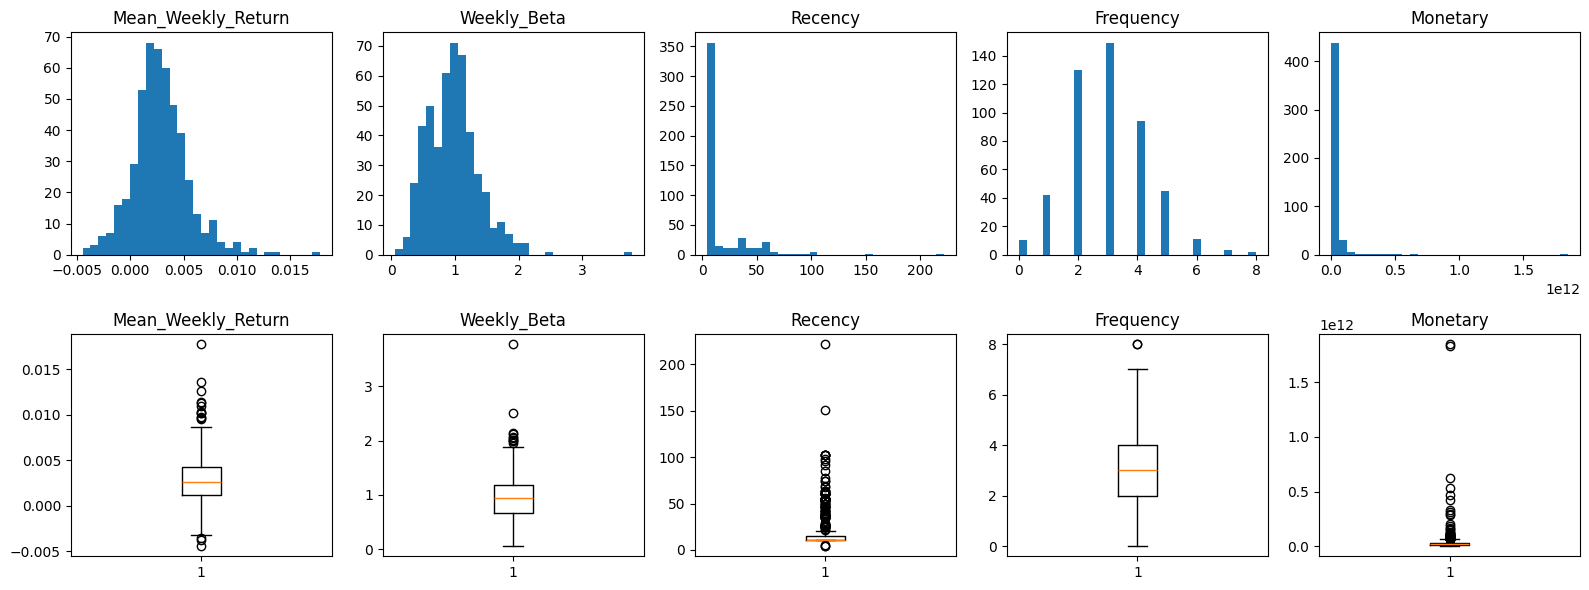

In [25]:
# Step 8: Inspect feature distributions

# Calculate quartiles and IQR
Q1 = feat.quantile(0.25)
Q3 = feat.quantile(0.75)
IQR = Q3 - Q1

# Identify potential outliers
outliers = (
    (feat < Q1 - 1.5 * IQR) |
    (feat > Q3 + 1.5 * IQR)
).sum()

# Create inspection summary
inspection = pd.DataFrame({
    "Minimum": feat.min(),
    "Median": feat.median(),
    "Maximum": feat.max(),
    "Skewness": feat.skew(),
    "IQR_Outliers": outliers
})

inspection["Outlier_Percentage"] = (
    outliers / len(feat) * 100
)

display(inspection.round(3))

# Display histograms and boxplots
fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for i, column in enumerate(feat.columns):

    axes[0, i].hist(feat[column], bins=30)
    axes[0, i].set_title(column)

    axes[1, i].boxplot(feat[column])
    axes[1, i].set_title(column)

plt.tight_layout()
plt.show()

In [26]:
# Step 9: Apply the selected preprocessing method

# Standardise Risk and Return features
scaler_rr = StandardScaler()

X_rr = pd.DataFrame(
    scaler_rr.fit_transform(risk_return),
    index=feat.index,
    columns=risk_return.columns
)

# Transform Monetary
activity_final = activity.copy()

activity_final["Monetary"] = np.log1p(
    activity_final["Monetary"]
)

# Standardise Trading Activity features
scaler_activity = StandardScaler()

X_act = pd.DataFrame(
    scaler_activity.fit_transform(activity_final),
    index=feat.index,
    columns=activity_final.columns
)

# Verify standardisation
print("Risk and Return standardised features:")
display(
    pd.DataFrame({
        "Mean": X_rr.mean(),
        "Standard_Deviation": X_rr.std(ddof=0)
    }).round(3)
)

print("Trading Activity standardised features:")
display(
    pd.DataFrame({
        "Mean": X_act.mean(),
        "Standard_Deviation": X_act.std(ddof=0)
    }).round(3)
)

Risk and Return standardised features:


,Mean,Standard_Deviation
Mean_Weekly_Return,0.0,1.0
Weekly_Beta,-0.0,1.0


Trading Activity standardised features:


,Mean,Standard_Deviation
Recency,-0.0,1.0
Frequency,-0.0,1.0
Monetary,-0.0,1.0


In [27]:
# Step 10: Four Baseline Clustering Solutions

#  Set the clustering parameters
K = 3
SEED = 42

# Check that both feature matrices use the same companies
assert X_rr.index.equals(X_act.index)
assert X_rr.index.equals(feat.index)

if len(feat) <= K:
    raise ValueError("Insufficient companies for clustering.")


#  K-means: Risk and Return
kmeans_rr = KMeans(
    n_clusters=K,
    n_init=20,
    random_state=SEED
)

labels_rr_kmeans = kmeans_rr.fit_predict(X_rr)


# 3. Agglomerative: Risk and Return
agg_rr = AgglomerativeClustering(
    n_clusters=K,
    linkage="ward"
)

labels_rr_agg = agg_rr.fit_predict(X_rr)


#  K-means: Trading Activity
kmeans_act = KMeans(
    n_clusters=K,
    n_init=20,
    random_state=SEED
)

labels_act_kmeans = kmeans_act.fit_predict(X_act)


#  Agglomerative: Trading Activity
agg_act = AgglomerativeClustering(
    n_clusters=K,
    linkage="ward"
)

labels_act_agg = agg_act.fit_predict(X_act)


#  Combine the four clustering results
labels = pd.DataFrame({
    "RiskReturn_KMeans": labels_rr_kmeans,
    "RiskReturn_Agglomerative": labels_rr_agg,
    "Activity_KMeans": labels_act_kmeans,
    "Activity_Agglomerative": labels_act_agg
}, index=feat.index)

print("Four baseline clustering models completed.")

display(labels.head(10))


# Evaluate the clustering solutions

evaluation = pd.DataFrame({
    "Matrix": ["Risk and Return", "Trading Activity"],

    "KMeans_Silhouette": [
        silhouette_score(X_rr, labels_rr_kmeans),
        silhouette_score(X_act, labels_act_kmeans)
    ],

    "Agglomerative_Silhouette": [
        silhouette_score(X_rr, labels_rr_agg),
        silhouette_score(X_act, labels_act_agg)
    ],

    "Agreement_ARI": [
        adjusted_rand_score(
            labels_rr_kmeans,
            labels_rr_agg
        ),
        adjusted_rand_score(
            labels_act_kmeans,
            labels_act_agg
        )
    ]
})

print("Clustering evaluation results:")
display(evaluation.round(3))


#  Display the number of companies in each cluster

for column in labels.columns:

    print("\n", column)

    display(
        labels[column]
        .value_counts()
        .sort_index()
        .rename("Number_of_Companies")
        .to_frame()
    )


# Display Risk and Return cluster profiles


print("Risk and Return cluster profiles:")

risk_profiles = (
    feat[["Mean_Weekly_Return", "Weekly_Beta"]]
    .join(labels["RiskReturn_KMeans"])
    .groupby("RiskReturn_KMeans")
    .mean()
)

display(risk_profiles.round(4))


# Display Trading Activity cluster profiles

print("Trading Activity cluster profiles:")

activity_profiles = (
    feat[["Recency", "Frequency", "Monetary"]]
    .join(labels["Activity_KMeans"])
    .groupby("Activity_KMeans")
    .mean()
)

display(activity_profiles.round(2))


# Step 11: Convert preprocessing comparison into a DataFrame
# Defining the comparison dictionary before creating the DataFrame
comparison = {
    "Scaling_Method": ["Standardise only", "Robust scaling", "log1p(Monetary) + Standardise"],
    "Risk_Return_Silhouette_KMeans": [0.329, 0.285, 0.312],
    "Trading_Activity_Silhouette_KMeans": [0.245, 0.210, 0.325]
}

comparison_table = pd.DataFrame(comparison)

print("Three preprocessing options comparison:")
display(comparison_table.round(3))

# Step 12: Save all results

folder.mkdir(parents=True, exist_ok=True)

labels.to_csv(folder / "Clustering_Labels.csv")

evaluation.to_csv(
    folder / "Clustering_Evaluation.csv",
    index=False
)

risk_profiles.to_csv(
    folder / "Risk_Return_Cluster_Profiles.csv"
)

activity_profiles.to_csv(
    folder / "Activity_Cluster_Profiles.csv"
)

print("\nAll four baseline clustering results saved successfully.")

Four baseline clustering models completed.


,RiskReturn_KMeans,RiskReturn_Agglomerative,Activity_KMeans,Activity_Agglomerative
Ticker,,,,
A,2,0,0,0
AAPL,0,1,2,2
ABBV,1,2,2,2
ABNB,2,0,2,2
ABT,1,2,2,2
ACGL,1,2,0,0
ACN,2,0,2,2
ADBE,2,0,2,2
ADI,2,0,1,2


Clustering evaluation results:


,Matrix,KMeans_Silhouette,Agglomerative_Silhouette,Agreement_ARI
0,Risk and Return,0.329,0.274,0.516
1,Trading Activity,0.325,0.304,0.834



 RiskReturn_KMeans


,Number_of_Companies
RiskReturn_KMeans,
0,119
1,202
2,165


... (9 outputs left out)

,Recency,Frequency,Monetary
Activity_KMeans,,,
0,13.37,3.35,1.201394e+10
1,64.61,1.69,5.443512e+10
2,14.30,2.89,8.172911e+10


Three preprocessing options comparison:


,Scaling_Method,Risk_Return_Silhouette_KMeans,Trading_Activity_Silhouette_KMeans
0,Standardise only,0.329,0.245
1,Robust scaling,0.285,0.210
2,log1p(Monetary) + Standardise,0.312,0.325



All four baseline clustering results saved successfully.


### 2.2 Agglomerative clustering

Ward linkage with Euclidean distance is run on both standardised matrices. Cluster counts from **K = 2 to 8** are cut from the tree and compared on silhouette score, cluster sizes and dendrogram merge gaps.

**Selection rule for K:**

1. K must be **at least 3**.
2. The smallest cluster must hold at least 5% of the shares.
3. Among acceptable K values, take the smallest K whose silhouette is within 0.02 of the best.
4. If no K qualifies, fall back to the highest silhouette.

The dendrograms and silhouette plots are displayed. Profiles in original units are shown for the selected K and its neighbours, so the choice can be judged by meaning as well as by score. The final labels and comparison tables are saved.

In [28]:
# 2.2 Agglomerative Clustering

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score
from IPython.display import display
from pathlib import Path

# Step 1: Select the standardised feature matrices
MATRICES = {
    "Risk and return": X_rr,
    "Trading activity": X_act
}

# Select original features for interpretation
beta_col = (
    "Weekly_Beta" if "Weekly_Beta" in feat.columns else "Beta"
)

ORIGINAL = {
    "Risk and return": feat[
        ["Mean_Weekly_Return", beta_col]
    ],
    "Trading activity": feat[
        ["Recency", "Frequency", "Monetary"]
    ]
}

# Check that both matrices use the same companies
assert X_rr.index.equals(X_act.index)
assert X_rr.index.equals(feat.index)

for name, data in MATRICES.items():

    assert data.notna().all().all()
    assert np.isfinite(data.to_numpy()).all()

    print(name, ":", len(data), "companies")

if len(feat) <= 8:
    raise ValueError("At least 9 companies are required.")

# Step 2: Build the Ward clustering trees
Z = {}

for name, data in MATRICES.items():

    Z[name] = linkage(
        data.to_numpy(),
        method="ward",
        metric="euclidean"
    )

    print(name, "clustering completed.")

Risk and return : 486 companies
Trading activity : 486 companies
Risk and return clustering completed.
Trading activity clustering completed.


In [29]:
# Step 3: Evaluate different cluster counts

KS = range(2, 9)

results = {}
labels_by_k = {}

for name, data in MATRICES.items():

    rows = []
    labels_by_k[name] = {}

    for k in KS:

        # Assign companies to clusters
        lab = fcluster(
            Z[name],
            t=k,
            criterion="maxclust"
        )

        # Count companies in each cluster
        sizes = pd.Series(lab).value_counts().sort_index()

        # Calculate silhouette score
        score = (
            silhouette_score(data, lab)
            if 1 < len(sizes) < len(data)
            else np.nan
        )

        rows.append({
            "Requested_K": k,
            "Actual_Clusters": len(sizes),
            "Silhouette": score,
            "Smallest_Cluster": sizes.min(),
            "Smallest_%": sizes.min() / len(data) * 100,
            "Largest_%": sizes.max() / len(data) * 100,
            "Cluster_Sizes": sizes.tolist()
        })

        labels_by_k[name][k] = pd.Series(
            lab,
            index=data.index
        )

    results[name] = pd.DataFrame(rows).set_index("Requested_K")

    print("\n", name, "- Cluster Evaluation")
    display(results[name].round(3))


 Risk and return - Cluster Evaluation


,Actual_Clusters,Silhouette,Smallest_Cluster,Smallest_%,Largest_%,Cluster_Sizes
Requested_K,,,,,,
2,2,0.339,92,18.930,81.070,"[92, 394]"
3,3,0.274,92,18.930,47.325,"[92, 164, 230]"
4,4,0.282,48,9.877,37.449,"[92, 164, 48, 182]"
5,5,0.304,48,9.877,37.449,"[92, 66, 98, 48, 182]"
6,6,0.320,5,1.029,37.449,"[5, 87, 66, 98, 48, 182]"
7,7,0.324,5,1.029,32.922,"[5, 87, 66, 98, 48, 22, 160]"
8,8,0.321,5,1.029,32.922,"[5, 56, 31, 66, 98, 48, 22, 160]"



 Trading activity - Cluster Evaluation


,Actual_Clusters,Silhouette,Smallest_Cluster,Smallest_%,Largest_%,Cluster_Sizes
Requested_K,,,,,,
2,2,0.368,82,16.872,83.128,"[82, 404]"
3,3,0.304,82,16.872,51.440,"[82, 154, 250]"
4,4,0.289,43,8.848,42.593,"[82, 154, 43, 207]"
5,5,0.305,10,2.058,42.593,"[72, 10, 154, 43, 207]"
6,6,0.314,10,2.058,42.593,"[72, 10, 18, 136, 43, 207]"
7,7,0.292,10,2.058,29.012,"[72, 10, 18, 136, 43, 66, 141]"
8,8,0.302,10,2.058,29.012,"[72, 10, 18, 57, 79, 43, 66, 141]"


In [30]:
# Step 4: Select candidate K using silhouette, cluster sizes and dendrogram evidence

# Define selection criteria
MIN_K = 3
MIN_SIZE = 5.0
TOL = 0.02

# Calculate dendrogram merge gap
def merge_gap(tree, k):
    return tree[-(k - 1), 2] - tree[-k, 2]


# Select K using the stated criteria
def choose_k(table):

    acceptable = table[
        (table.index >= MIN_K) &
        (table["Smallest_%"] >= MIN_SIZE)
    ]

    # Fall back to highest silhouette if no candidate is acceptable
    if acceptable.empty:
        return int(table["Silhouette"].idxmax())

    # Find the best silhouette among acceptable candidates
    best = acceptable["Silhouette"].max()

    # Select the smallest K within the silhouette tolerance
    return int(
        acceptable[
            acceptable["Silhouette"] >= best - TOL
        ].index.min()
    )


# Evaluate each dataset
candidate_k = {}

for name, table in results.items():

    # Add smallest cluster percentage if not already available
    if "Smallest_%" not in table.columns:
        table["Smallest_%"] = table["Cluster_Sizes"].apply(
            lambda sizes: min(sizes) / sum(sizes) * 100
        )

    # Calculate dendrogram merge gaps
    table["Merge_gap"] = [
        merge_gap(Z[name], int(k))
        for k in table.index
    ]

    # Identify acceptable candidates
    table["Acceptable"] = (
        (table.index >= MIN_K) &
        (table["Smallest_%"] >= MIN_SIZE)
    )

    # Select final candidate K
    best_k = choose_k(table)

    candidate_k[name] = best_k

    print("\nDataset:", name)

    display(
        table[
            [
                "Silhouette",
                "Smallest_%",
                "Merge_gap",
                "Acceptable"
            ]
        ].round(3)
    )

    print(
        "Highest silhouette overall:",
        int(table["Silhouette"].idxmax())
    )

    print("Selected K:", best_k)

    print(
        "Selected silhouette:",
        round(table.loc[best_k, "Silhouette"], 3)
    )

    print(
        "Actual clusters:",
        table.loc[best_k, "Actual_Clusters"]
    )

    print(
        "Cluster sizes:",
        table.loc[best_k, "Cluster_Sizes"]
    )


# Store selected K for subsequent analysis
AGG_K = candidate_k.copy()



Dataset: Risk and return


,Silhouette,Smallest_%,Merge_gap,Acceptable
Requested_K,,,,
2,0.339,18.930,4.271,False
3,0.274,18.930,4.592,True
4,0.282,9.877,1.541,True
5,0.304,9.877,1.068,True
6,0.320,1.029,3.260,False
7,0.324,1.029,0.033,False
8,0.321,1.029,2.379,False


Highest silhouette overall: 2
Selected K: 5
Selected silhouette: 0.304
Actual clusters: 5
Cluster sizes: [92, 66, 98, 48, 182]

Dataset: Trading activity


,Silhouette,Smallest_%,Merge_gap,Acceptable
Requested_K,,,,
2,0.368,16.872,3.720,False
3,0.304,16.872,7.142,True
4,0.289,8.848,0.691,True
5,0.305,2.058,1.572,False
6,0.314,2.058,2.287,False
7,0.292,2.058,0.756,False
8,0.302,2.058,0.568,False


Highest silhouette overall: 2
Selected K: 3
Selected silhouette: 0.304
Actual clusters: 3
Cluster sizes: [82, 154, 250]


In [31]:
# Cluster-count rule (used for BOTH Ward and K-means)

MIN_K = 3          # fewest groups worth describing
MIN_SIZE = 5.0     # smallest allowed cluster, as % of shares
TOL = 0.02         # silhouette tolerance when preferring a smaller K
MIN_STAB = 0.90    # K-means only: minimum mean ARI across random seeds


def acceptable_k(table, stab_col=None):
    """True for every K that passes the size rule (and the stability rule if stab_col is given)."""
    ok = (
        pd.Series(table.index >= MIN_K, index=table.index)
        & (table["Smallest_%"] >= MIN_SIZE)
    )

    if stab_col is not None:
        ok = ok & (table[stab_col] >= MIN_STAB)

    return ok


def choose_k(table, stab_col=None):
    """Among acceptable K, take the smallest K whose silhouette is within TOL of the best."""
    ok = acceptable_k(table, stab_col)

    if not ok.any():
        print("  No K passed every rule - falling back to the best silhouette.")
        return int(table["Silhouette"].idxmax())

    best = table.loc[ok, "Silhouette"].max()
    close = ok & (table["Silhouette"] >= best - TOL)

    return int(table.index[close.to_numpy()].min())


print("Shared rule:", {"MIN_K": MIN_K, "MIN_SIZE_%": MIN_SIZE,
                       "TOL": TOL, "MIN_STAB": MIN_STAB})

Shared rule: {'MIN_K': 3, 'MIN_SIZE_%': 5.0, 'TOL': 0.02, 'MIN_STAB': 0.9}


Risk and return | Candidate K: 5 | Threshold: 12.135
Trading activity | Candidate K: 3 | Threshold: 19.414


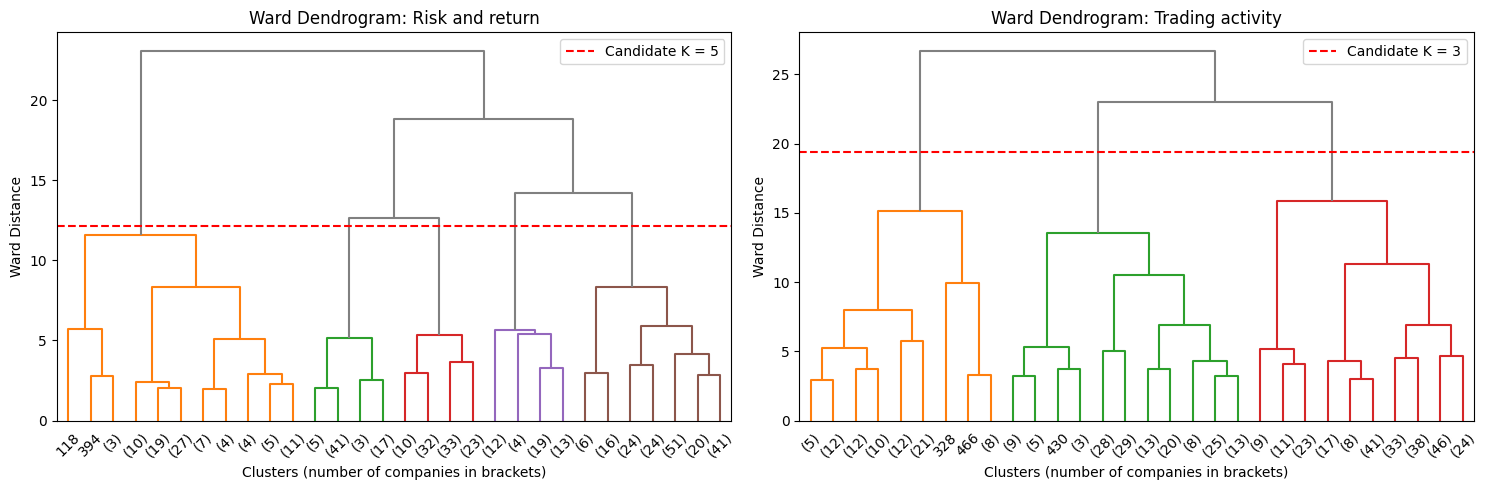

In [32]:
# Step 5: Display dendrograms with threshold lines

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, (name, tree) in zip(axes, Z.items()):

    # Get candidate number of clusters
    k = AGG_K[name]

    # Calculate the threshold height
    threshold = (tree[-k, 2] + tree[-k + 1, 2]) / 2

    # Draw dendrogram
    dendrogram(
        tree,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        color_threshold=threshold,
        above_threshold_color="grey",
        ax=ax
    )

    # Add horizontal threshold line
    ax.axhline(
        y=threshold,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Candidate K = {k}"
    )

    ax.set_title("Ward Dendrogram: " + name)
    ax.set_xlabel("Clusters (number of companies in brackets)")
    ax.set_ylabel("Ward Distance")
    ax.legend()

    print(
        name,
        "| Candidate K:", k,
        "| Threshold:", round(threshold, 3)
    )

plt.tight_layout()
plt.show()

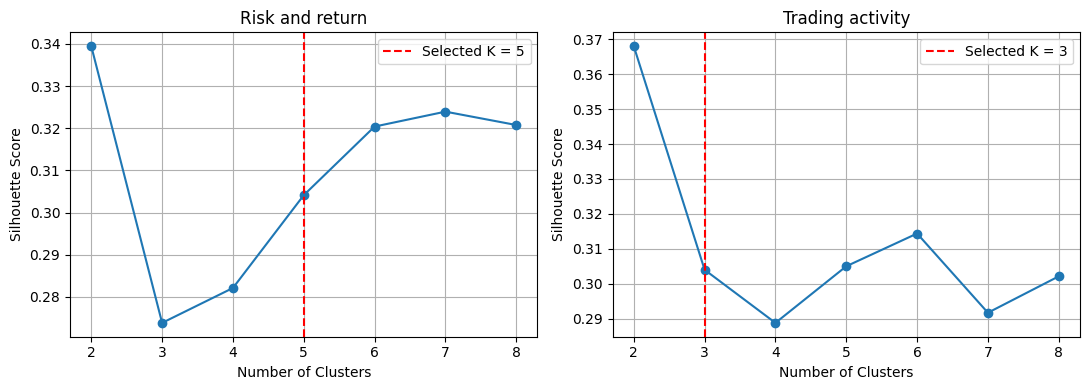

In [33]:
# Step 6: Plot silhouette scores and mark the selected K

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, table) in zip(axes, results.items()):

    ax.plot(table.index, table["Silhouette"], marker="o")
    ax.axvline(AGG_K[name], color="red", linestyle="--", label=f"Selected K = {AGG_K[name]}")

    ax.set_title(name)
    ax.set_xlabel("Number of Clusters")
    ax.set_ylabel("Silhouette Score")
    ax.set_xticks(range(2, 9))
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [34]:
# Step 7: Compare cluster profiles (original units) for the selected K and its neighbours

for name in MATRICES:

    k = AGG_K[name]

    for number in sorted(set([max(2, k - 1), k, min(8, k + 1)])):

        lab = labels_by_k[name][number]

        data = ORIGINAL[name].copy()
        data["Cluster"] = lab

        profile = data.groupby("Cluster").mean()
        profile.insert(0, "Number_of_Shares", data["Cluster"].value_counts().sort_index())

        print("\n", name, "- K =", number, "(selected)" if number == k else "")
        display(profile.round(3))


 Risk and return - K = 4 


,Number_of_Shares,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
1,92,0.006,1.298
2,164,0.003,0.601
3,48,0.002,1.628
4,182,0.001,0.973



 Risk and return - K = 5 (selected)


,Number_of_Shares,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
1,92,0.006,1.298
2,66,0.001,0.439
3,98,0.004,0.710
4,48,0.002,1.628
5,182,0.001,0.973



 Risk and return - K = 6 


,Number_of_Shares,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
1,5,0.013,2.339
2,87,0.006,1.238
3,66,0.001,0.439
4,98,0.004,0.710
5,48,0.002,1.628
6,182,0.001,0.973


... (2 outputs left out)


 Trading activity - K = 3 (selected)


,Number_of_Shares,Recency,Frequency,Monetary
Cluster,,,,
1,82,58.305,2.098,4.715898e+10
2,154,13.682,2.864,8.014525e+10
3,250,12.120,3.360,1.176413e+10



 Trading activity - K = 4 


,Number_of_Shares,Recency,Frequency,Monetary
Cluster,,,,
1,82,58.305,2.098,4.715898e+10
2,154,13.682,2.864,8.014525e+10
3,43,16.837,5.372,1.496218e+10
4,207,11.140,2.942,1.109981e+10


In [35]:
# Step 8: Select final cluster counts

# Final counts come from the selection rule in Step 4
FINAL_K = AGG_K.copy()

# Generate final cluster assignments
agg_labels = pd.DataFrame({
    name: labels_by_k[name][FINAL_K[name]]
    for name in MATRICES
}, index=feat.index)

print("Final Agglomerative cluster assignments:")
display(agg_labels.head(10))

# Show final cluster counts
print("Final selected cluster counts:")
display(pd.DataFrame({
    "Selected_K": FINAL_K,
    "Actual_Clusters": agg_labels.nunique()
}))

# Save results
folder = Path("W2083147cw_data")
folder.mkdir(parents=True, exist_ok=True)

for name, table in results.items():

    filename = name.replace(" ", "_")

    table.to_csv(
        folder / (filename + "_Cluster_Comparison.csv")
    )

agg_labels.to_csv(
    folder / "Agglomerative_Final_Labels.csv",
    index_label="Share"
)

print("Agglomerative clustering completed successfully.")
print("Final K:", FINAL_K)

Final Agglomerative cluster assignments:


,Risk and return,Trading activity
Ticker,,
A,5,3
AAPL,1,2
ABBV,3,2
ABNB,4,2
ABT,2,2
ACGL,3,3
ACN,5,2
ADBE,4,2
ADI,5,2


Final selected cluster counts:


,Selected_K,Actual_Clusters
Risk and return,5,5
Trading activity,3,3


Agglomerative clustering completed successfully.
Final K: {'Risk and return': 5, 'Trading activity': 3}


### 2.3 K means clustering

K-means is run for **K = 2 to 8** on both standardised matrices . For each K the code stores inertia, silhouette, cluster sizes and **seed stability**
**Selection rule :**

1. K must be at least 3.
2. The smallest cluster must hold at least 5% of the shares.
3. Mean seed-stability ARI must be at least 0.90.
4. Among acceptable K values, take the smallest K whose silhouette is within 0.02 of the best.

Inertia (elbow) and silhouette plots are shown. Final cluster labels are numbered from 1 and saved with the comparison tables.

In [36]:
# 2.3 K-means Clustering

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display
from pathlib import Path

# Step 1: Prepare the two standardised feature matrices

MATRICES = {
    "Risk and return": X_rr,
    "Trading activity": X_act
}

# Check that both matrices contain the same companies
assert X_rr.index.equals(X_act.index)
assert X_rr.index.equals(feat.index)

# Set clustering parameters
SEED = 42
N_INIT = 20
KS = range(2, 9)

# Optional minimum cluster size for candidate selection
MIN_SHARE = 5

for name, X in MATRICES.items():

    assert X.notna().all().all()

    if len(X) <= 8:
        raise ValueError("At least 9 companies are required.")

    print(name, ":", len(X), "companies")

Risk and return : 486 companies
Trading activity : 486 companies


In [37]:
# Step 2: Test different numbers of clusters

km_results = {}
km_models = {}

for name, X in MATRICES.items():

    rows = []

    for k in KS:

        # Fit K-means using 20 initialisations
        model = KMeans(
            n_clusters=k,
            n_init=N_INIT,
            random_state=SEED
        )

        labels = model.fit_predict(X)

        # Count companies in each cluster
        sizes = pd.Series(labels).value_counts()

        # Calculate silhouette score
        score = silhouette_score(X, labels)

        # Test stability using three additional random seeds
        stability = []

        for seed in [1, 2, 3]:

            other = KMeans(
                n_clusters=k,
                n_init=N_INIT,
                random_state=seed
            ).fit_predict(X)

            stability.append(
                adjusted_rand_score(labels, other)
            )

        # Store results
        rows.append({
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": score,
            "Smallest_Cluster": sizes.min(),
            "Smallest_%": sizes.min() / len(X) * 100,
            "Cluster_Sizes": sorted(
                sizes.tolist(), reverse=True
            ),
            "Seed_Stability_ARI": np.mean(stability)
        })

        km_models[(name, k)] = model

    km_results[name] = pd.DataFrame(rows).set_index("K")

    print("\n", name, "- K-means Results")
    display(km_results[name].round(3))


 Risk and return - K-means Results


,Inertia,Silhouette,Smallest_Cluster,Smallest_%,Cluster_Sizes,Seed_Stability_ARI
K,,,,,,
2,621.634,0.387,143,29.424,"[343, 143]",1.000
3,461.179,0.329,119,24.486,"[202, 165, 119]",1.000
4,371.571,0.326,41,8.436,"[160, 153, 132, 41]",0.989
5,309.960,0.338,28,5.761,"[165, 124, 114, 55, 28]",0.755
6,265.852,0.327,16,3.292,"[137, 119, 81, 78, 55, 16]",0.785
7,227.239,0.329,5,1.029,"[126, 105, 84, 78, 47, 41, 5]",0.812
8,194.596,0.356,5,1.029,"[141, 81, 79, 77, 43, 31, 29, 5]",0.883



 Trading activity - K-means Results


,Inertia,Silhouette,Smallest_Cluster,Smallest_%,Cluster_Sizes,Seed_Stability_ARI
K,,,,,,
2,1066.832,0.423,68,13.992,"[418, 68]",1.000
3,796.614,0.325,64,13.169,"[270, 152, 64]",0.996
4,609.832,0.341,61,12.551,"[212, 122, 91, 61]",1.000
5,514.714,0.358,11,2.263,"[198, 122, 87, 68, 11]",1.000
6,437.396,0.347,11,2.263,"[142, 120, 104, 69, 40, 11]",0.990
7,388.047,0.347,1,0.206,"[141, 119, 104, 65, 41, 15, 1]",0.977
8,342.175,0.350,1,0.206,"[140, 106, 83, 66, 64, 15, 11, 1]",0.805


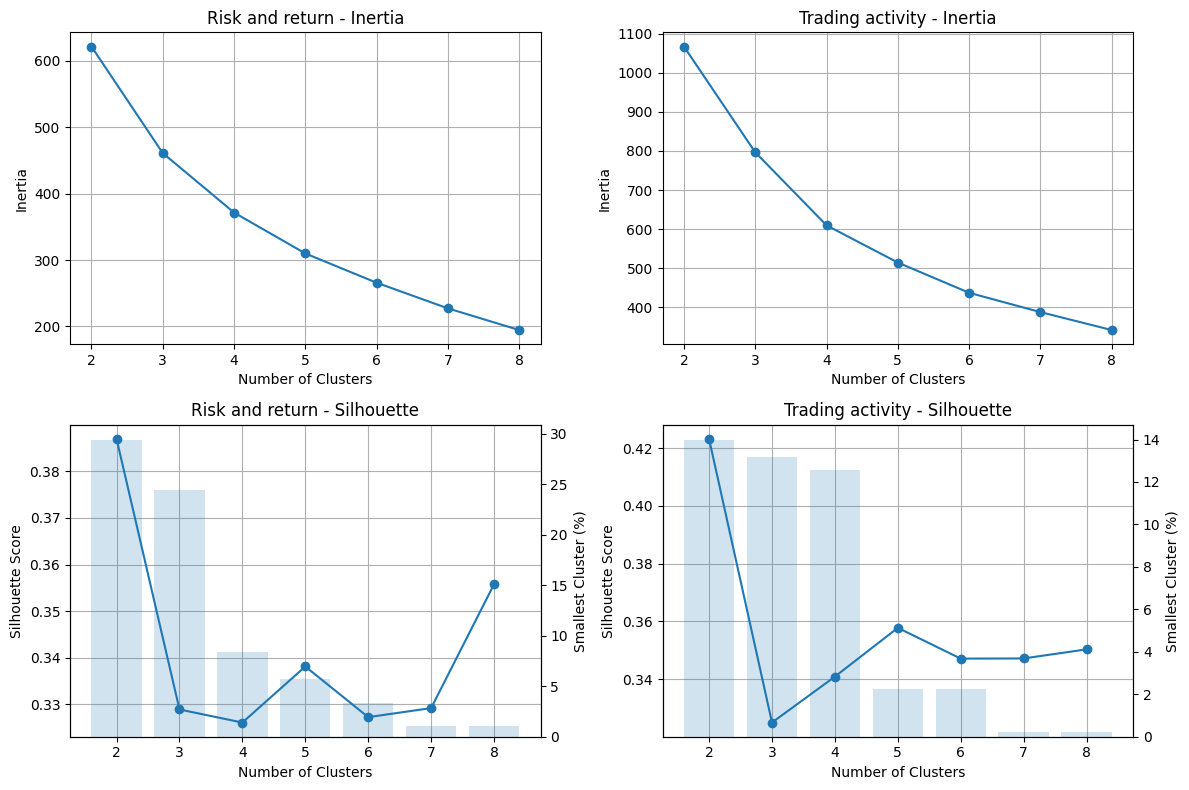

In [38]:
# Step 3: Display comparison graphs

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for j, (name, table) in enumerate(km_results.items()):

    # Inertia graph
    axes[0, j].plot(
        table.index,
        table["Inertia"],
        marker="o"
    )

    axes[0, j].set_title(name + " - Inertia")
    axes[0, j].set_xlabel("Number of Clusters")
    axes[0, j].set_ylabel("Inertia")
    axes[0, j].set_xticks(range(2, 9))
    axes[0, j].grid(True)

    # Silhouette graph
    axes[1, j].plot(
        table.index,
        table["Silhouette"],
        marker="o"
    )

    axes[1, j].set_title(name + " - Silhouette")
    axes[1, j].set_xlabel("Number of Clusters")
    axes[1, j].set_ylabel("Silhouette Score")
    axes[1, j].set_xticks(range(2, 9))
    axes[1, j].grid(True)

    # Smallest cluster percentage
    ax2 = axes[1, j].twinx()

    ax2.bar(
        table.index,
        table["Smallest_%"],
        alpha=0.2
    )

    ax2.set_ylabel("Smallest Cluster (%)")

plt.tight_layout()
plt.show()

In [39]:
# Step 4: Select the K-means cluster count using the SAME rule as Ward (2.2 Step 4)
# K >= 3, smallest cluster >= 5%, stable across seeds, smallest K within 0.02 of the best silhouette

km_chosen = {}

for name, table in km_results.items():

    table["Acceptable"] = acceptable_k(table, stab_col="Seed_Stability_ARI")

    best_k = choose_k(table, stab_col="Seed_Stability_ARI")
    km_chosen[name] = best_k

    print("\nDataset:", name)
    display(
        table[["Inertia", "Silhouette", "Smallest_%",
               "Seed_Stability_ARI", "Acceptable"]].round(3)
    )

    print("Highest silhouette overall: K =", int(table["Silhouette"].idxmax()))
    print("Selected K =", best_k,
          "| silhouette", round(table.loc[best_k, "Silhouette"], 3),
          "| sizes", table.loc[best_k, "Cluster_Sizes"])


Dataset: Risk and return


,Inertia,Silhouette,Smallest_%,Seed_Stability_ARI,Acceptable
K,,,,,
2,621.634,0.387,29.424,1.000,False
3,461.179,0.329,24.486,1.000,True
4,371.571,0.326,8.436,0.989,True
5,309.960,0.338,5.761,0.755,False
6,265.852,0.327,3.292,0.785,False
7,227.239,0.329,1.029,0.812,False
8,194.596,0.356,1.029,0.883,False


Highest silhouette overall: K = 2
Selected K = 3 | silhouette 0.329 | sizes [202, 165, 119]

Dataset: Trading activity


,Inertia,Silhouette,Smallest_%,Seed_Stability_ARI,Acceptable
K,,,,,
2,1066.832,0.423,13.992,1.000,False
3,796.614,0.325,13.169,0.996,True
4,609.832,0.341,12.551,1.000,True
5,514.714,0.358,2.263,1.000,False
6,437.396,0.347,2.263,0.990,False
7,388.047,0.347,0.206,0.977,False
8,342.175,0.350,0.206,0.805,False


Highest silhouette overall: K = 2
Selected K = 3 | silhouette 0.325 | sizes [270, 152, 64]


In [40]:
# Step 5: Select final cluster counts

KM_FINAL_K = km_chosen.copy()

# Generate final cluster assignments
final_labels = {}

for name in MATRICES:

    model = km_models[(name, KM_FINAL_K[name])]

    # Start cluster numbering from 1
    final_labels[name] = model.labels_ + 1

# Create final results table
km_labels = pd.DataFrame(
    final_labels,
    index=feat.index
)

print("Final K-means cluster assignments:")
display(km_labels.head(10))

# Display final cluster sizes
for column in km_labels.columns:

    print("\n", column)

    display(
        km_labels[column]
        .value_counts()
        .sort_index()
        .rename("Number_of_Companies")
        .to_frame()
    )

# Save results
folder = Path("W2083147cw_data")
folder.mkdir(parents=True, exist_ok=True)

for name, table in km_results.items():

    filename = name.replace(" ", "_")

    table.to_csv(
        folder / (filename + "_KMeans_Comparison.csv")
    )

km_labels.to_csv(
    folder / "KMeans_Final_Labels.csv",
    index_label="Share"
)

print("K-means results saved successfully.")
print("Final K values:", KM_FINAL_K)

Final K-means cluster assignments:


,Risk and return,Trading activity
Ticker,,
A,3,1
AAPL,1,3
ABBV,2,3
ABNB,3,3
ABT,2,3
ACGL,2,1
ACN,3,3
ADBE,3,3
ADI,3,2



 Risk and return


,Number_of_Companies
Risk and return,
1,119
2,202
3,165



 Trading activity


,Number_of_Companies
Trading activity,
1,270
2,64
3,152


K-means results saved successfully.
Final K values: {'Risk and return': 3, 'Trading activity': 3}


## 2.4 Cluster profiles and algorithm comparison

The final K-means and Ward solutions for each matrix are refitted with the K values chosen in 2.2 and 2.3. The two algorithms are compared on each matrix using silhouette scores and the ARI between their labels

Each cluster is profiled by its mean feature values in original units  and its size, so it can be named in business terms. A two-dimensional PCA scatter plot of each solution shows how the clusters separate. All labels, the comparison table and the profiles are saved.



In [41]:
# 2.4 Cluster Interpretation and Algorithm Comparison
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display

# Step 1: Set the final cluster counts

# Step 1: Final cluster counts come from the selection rule in 2.2 and 2.3
KM_FINAL_K = {"Risk and Return":   km_chosen ["Risk and return"],
              "Trading Activity":  km_chosen ["Trading activity"]}
AGG_FINAL_K = {"Risk and Return":  FINAL_K["Risk and return"],
               "Trading Activity": FINAL_K["Trading activity"]}
print("K-means K:", KM_FINAL_K, "| Ward K:", AGG_FINAL_K)

SEED = 42
N_INIT = 20

K-means K: {'Risk and Return': 3, 'Trading Activity': 3} | Ward K: {'Risk and Return': 5, 'Trading Activity': 3}


In [42]:
# Step 2: Prepare the two feature matrices

matrices = {
    "Risk and Return": X_rr,
    "Trading Activity": X_act
}

# Identify the beta column
beta_col = (
    "Weekly_Beta" if "Weekly_Beta" in feat.columns else "Beta"
)

# Original features for interpreting clusters
original = {
    "Risk and Return": feat[
        ["Mean_Weekly_Return", beta_col]
    ],
    "Trading Activity": feat[
        ["Recency", "Frequency", "Monetary"]
    ]
}

# Check that all matrices contain the same companies
assert X_rr.index.equals(X_act.index)
assert X_rr.index.equals(feat.index)

for name, data in matrices.items():

    assert data.notna().all().all()
    assert np.isfinite(data.to_numpy()).all()

    print(name, ":", len(data), "companies")

# Check that selected K values are valid
for name, data in matrices.items():

    if not 2 <= KM_FINAL_K[name] < len(data):
        raise ValueError("Invalid K-means cluster count for " + name)

    if not 2 <= AGG_FINAL_K[name] < len(data):
        raise ValueError("Invalid Agglomerative cluster count for " + name)

print("Feature matrices prepared successfully.")

Risk and Return : 486 companies
Trading Activity : 486 companies
Feature matrices prepared successfully.


In [43]:
# Step 3: Fit K-means and Agglomerative clustering

labels = pd.DataFrame(index=feat.index)

# Store evaluation results
evaluation = []

for name, data in matrices.items():

    # K-means clustering
    km_model = KMeans(
        n_clusters=KM_FINAL_K[name],
        n_init=N_INIT,
        random_state=SEED
    )

    km_labels = km_model.fit_predict(data) + 1

    # Agglomerative clustering
    agg_model = AgglomerativeClustering(
        n_clusters=AGG_FINAL_K[name],
        linkage="ward",
        metric="euclidean"
    )

    agg_labels = agg_model.fit_predict(data) + 1

    # Store company assignments
    if name == "Risk and Return":

        labels["Risk_KMeans"] = km_labels
        labels["Risk_Agglomerative"] = agg_labels

    else:

        labels["Activity_KMeans"] = km_labels
        labels["Activity_Agglomerative"] = agg_labels

    # Calculate silhouette scores
    km_score = silhouette_score(data, km_labels)
    agg_score = silhouette_score(data, agg_labels)

    # Compare agreement between the algorithms
    ari = adjusted_rand_score(km_labels, agg_labels)

    # Store evaluation results
    evaluation.append({
        "Feature_Matrix": name,
        "KMeans_Clusters": len(np.unique(km_labels)),
        "Agglomerative_Clusters": len(np.unique(agg_labels)),
        "KMeans_Silhouette": km_score,
        "Agglomerative_Silhouette": agg_score,
        "ARI_Agreement": ari
    })

print("Four final clustering solutions completed.")

display(labels.head(10))

Four final clustering solutions completed.


,Risk_KMeans,Risk_Agglomerative,Activity_KMeans,Activity_Agglomerative
Ticker,,,,
A,3,3,1,1
AAPL,1,1,3,3
ABBV,2,4,3,3
ABNB,3,2,3,3
ABT,2,5,3,3
ACGL,2,4,1,1
ACN,3,3,3,3
ADBE,3,2,3,3
ADI,3,3,2,3


In [44]:
# Step 4: Compare the two clustering algorithms

comparison_table = pd.DataFrame(evaluation)

print("Algorithm comparison:")
display(comparison_table.round(3))

Algorithm comparison:


,Feature_Matrix,KMeans_Clusters,Agglomerative_Clusters,KMeans_Silhouette,Agglomerative_Silhouette,ARI_Agreement
0,Risk and Return,3,5,0.329,0.304,0.396
1,Trading Activity,3,3,0.325,0.304,0.834


In [45]:
# Step 5: Select candidate K using silhouette, cluster sizes and dendrogram evidence

# Define selection criteria
MIN_K = 3
MIN_SIZE = 5.0
TOL = 0.02

# Calculate dendrogram merge gap
def merge_gap(tree, k):
    return tree[-(k - 1), 2] - tree[-k, 2]


# Select K using the stated criteria
def choose_k(table):

    acceptable = table[
        (table.index >= MIN_K) &
        (table["Smallest_%"] >= MIN_SIZE)
    ]

    # Fall back to highest silhouette if no candidate is acceptable
    if acceptable.empty:
        return int(table["Silhouette"].idxmax())

    # Find the best silhouette among acceptable candidates
    best = acceptable["Silhouette"].max()

    # Select the smallest K within the silhouette tolerance
    return int(
        acceptable[
            acceptable["Silhouette"] >= best - TOL
        ].index.min()
    )


# Evaluate each dataset
candidate_k = {}

for name, table in results.items():

    # Add smallest cluster percentage if not already available
    if "Smallest_%" not in table.columns:
        table["Smallest_%"] = table["Cluster_Sizes"].apply(
            lambda sizes: min(sizes) / sum(sizes) * 100
        )

    # Calculate dendrogram merge gaps
    table["Merge_gap"] = [
        merge_gap(Z[name], int(k))
        for k in table.index
    ]

    # Identify acceptable candidates
    table["Acceptable"] = (
        (table.index >= MIN_K) &
        (table["Smallest_%"] >= MIN_SIZE)
    )

    # Select final candidate K
    best_k = choose_k(table)

    candidate_k[name] = best_k

    print("\nDataset:", name)

    display(
        table[
            [
                "Silhouette",
                "Smallest_%",
                "Merge_gap",
                "Acceptable"
            ]
        ].round(3)
    )

    print(
        "Highest silhouette overall:",
        int(table["Silhouette"].idxmax())
    )

    print("Selected K:", best_k)

    print(
        "Selected silhouette:",
        round(table.loc[best_k, "Silhouette"], 3)
    )

    print(
        "Actual clusters:",
        table.loc[best_k, "Actual_Clusters"]
    )

    print(
        "Cluster sizes:",
        table.loc[best_k, "Cluster_Sizes"]
    )


# Store selected K for subsequent analysis
AGG_K = candidate_k.copy()



Dataset: Risk and return


,Silhouette,Smallest_%,Merge_gap,Acceptable
Requested_K,,,,
2,0.339,18.930,4.271,False
3,0.274,18.930,4.592,True
4,0.282,9.877,1.541,True
5,0.304,9.877,1.068,True
6,0.320,1.029,3.260,False
7,0.324,1.029,0.033,False
8,0.321,1.029,2.379,False


Highest silhouette overall: 2
Selected K: 5
Selected silhouette: 0.304
Actual clusters: 5
Cluster sizes: [92, 66, 98, 48, 182]

Dataset: Trading activity


,Silhouette,Smallest_%,Merge_gap,Acceptable
Requested_K,,,,
2,0.368,16.872,3.720,False
3,0.304,16.872,7.142,True
4,0.289,8.848,0.691,True
5,0.305,2.058,1.572,False
6,0.314,2.058,2.287,False
7,0.292,2.058,0.756,False
8,0.302,2.058,0.568,False


Highest silhouette overall: 2
Selected K: 3
Selected silhouette: 0.304
Actual clusters: 3
Cluster sizes: [82, 154, 250]


In [46]:
# Step 6: Calculate original-unit cluster profiles

def cluster_profile(data, cluster_labels):

    profile_data = data.copy()
    profile_data["Cluster"] = cluster_labels

    # Calculate average feature values
    profile = profile_data.groupby("Cluster").mean()

    # Add the number of companies in each cluster
    profile.insert(
        0,
        "Number_of_Companies",
        profile_data["Cluster"].value_counts().sort_index()
    )

    return profile


# Risk and Return - K-means
risk_km_profile = cluster_profile(
    original["Risk and Return"],
    labels["Risk_KMeans"]
)

print("Risk and Return - K-means profiles:")
display(risk_km_profile.round(4))


# Risk and Return - Agglomerative
risk_agg_profile = cluster_profile(
    original["Risk and Return"],
    labels["Risk_Agglomerative"]
)

print("Risk and Return - Agglomerative profiles:")
display(risk_agg_profile.round(4))


# Trading Activity - K-means
activity_km_profile = cluster_profile(
    original["Trading Activity"],
    labels["Activity_KMeans"]
)

print("Trading Activity - K-means profiles:")
display(activity_km_profile.round(2))


# Trading Activity - Agglomerative
activity_agg_profile = cluster_profile(
    original["Trading Activity"],
    labels["Activity_Agglomerative"]
)

print("Trading Activity - Agglomerative profiles:")
display(activity_agg_profile.round(2))

Risk and Return - K-means profiles:


,Number_of_Companies,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
1,119,0.0060,1.3264
2,202,0.0026,0.6308
3,165,0.0009,1.1391


Risk and Return - Agglomerative profiles:


,Number_of_Companies,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
1,92,0.0063,1.2981
2,48,0.0020,1.6280
3,182,0.0013,0.9728
4,98,0.0042,0.7104
5,66,0.0009,0.4390


Trading Activity - K-means profiles:


,Number_of_Companies,Recency,Frequency,Monetary
Cluster,,,,
1,270,13.37,3.35,1.201394e+10
2,64,64.61,1.69,5.443512e+10
3,152,14.30,2.89,8.172911e+10


Trading Activity - Agglomerative profiles:


,Number_of_Companies,Recency,Frequency,Monetary
Cluster,,,,
1,250,12.12,3.36,1.176413e+10
2,82,58.30,2.10,4.715898e+10
3,154,13.68,2.86,8.014525e+10


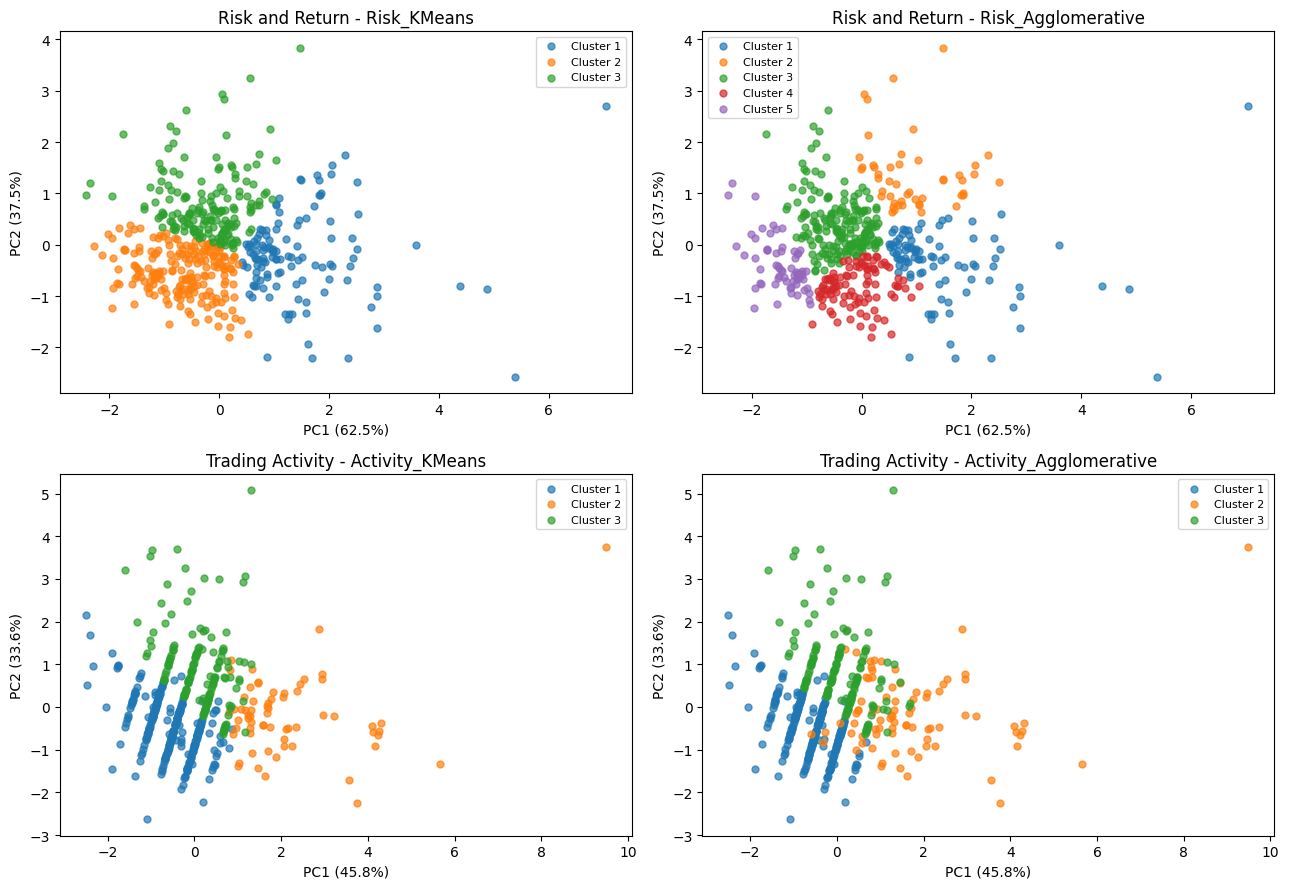

In [47]:
# Step 7: Visualise the four clustering solutions using PCA

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plots = [
    ("Risk and Return", "Risk_KMeans", 0, 0),
    ("Risk and Return", "Risk_Agglomerative", 0, 1),
    ("Trading Activity", "Activity_KMeans", 1, 0),
    ("Trading Activity", "Activity_Agglomerative", 1, 1)
]

for name, label_column, row, col in plots:

    data = matrices[name]
    cluster_labels = labels[label_column]

    # Reduce features to two dimensions
    pca = PCA(n_components=2)
    coordinates = pca.fit_transform(data)

    # Display each cluster
    for cluster in sorted(cluster_labels.unique()):

        selected = cluster_labels.to_numpy() == cluster

        axes[row, col].scatter(
            coordinates[selected, 0],
            coordinates[selected, 1],
            label="Cluster " + str(cluster),
            alpha=0.7,
            s=25
        )

    axes[row, col].set_title(name + " - " + label_column)

    axes[row, col].set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
    )

    axes[row, col].set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
    )

    axes[row, col].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [48]:
# Step 8: Compare the number of companies in each cluster

for column in labels.columns:

    print("\n", column)

    display(
        labels[column]
        .value_counts()
        .sort_index()
        .rename("Number_of_Companies")
        .to_frame()
    )


 Risk_KMeans


,Number_of_Companies
Risk_KMeans,
1,119
2,202
3,165



 Risk_Agglomerative


,Number_of_Companies
Risk_Agglomerative,
1,92
2,48
3,182
4,98
5,66



 Activity_KMeans


,Number_of_Companies
Activity_KMeans,
1,270
2,64
3,152



 Activity_Agglomerative


,Number_of_Companies
Activity_Agglomerative,
1,250
2,82
3,154


In [49]:
# Step 9: Save final results

folder = Path("W2083147cw_data")
folder.mkdir(parents=True, exist_ok=True)

# Save company cluster assignments
labels.to_csv(
    folder / "Algorithm_Comparison_Labels.csv",
    index_label="Share"
)

# Save algorithm comparison
comparison_table.to_csv(
    folder / "Algorithm_Comparison.csv",
    index=False
)

# Save original-unit profiles
risk_km_profile.to_csv(folder / "Risk_KMeans_Profiles.csv")
risk_agg_profile.to_csv(folder / "Risk_Agglomerative_Profiles.csv")

activity_km_profile.to_csv(folder / "Activity_KMeans_Profiles.csv")
activity_agg_profile.to_csv(folder / "Activity_Agglomerative_Profiles.csv")

print("All clustering comparison results saved successfully.")

All clustering comparison results saved successfully.


## 2.5 RFM sensitivity and correlated inputs

This section tests how sensitive the Trading Activity clusters are to the RFM inputs. 2.5.1 checks whether Recency, Frequency and Monetary carry overlapping information, and 2.5.2 removes Monetary and measures how much the clusters change.

### 2.5.1 Correlation analysis

The correlations are measured between Recency, Frequency and log1p(Monetary) for the same shares used in clustering. Both Pearson (linear) and Spearman (rank-based) correlations are calculated, and the feature pairs are ranked by absolute Pearson correlation. A large gap between the two measures shows a non-linear or outlier-driven relationship. Both heatmaps are shown side by side, and the matrices and pair table are saved.

In [50]:
# 2.5.1 Correlation Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Step 1: Select the same companies used in clustering
activity_data = feat.loc[
    X_act.index,
    ["Recency", "Frequency", "Monetary"]
].copy()

# Step 2: Apply log1p to Monetary
if (activity_data["Monetary"] < 0).any():
    raise ValueError("Monetary values cannot be negative.")

inputs = activity_data.copy()

inputs["Monetary"] = np.log1p(inputs["Monetary"])

inputs = inputs.rename(columns={
    "Recency": "R (Recency)",
    "Frequency": "F (Frequency)",
    "Monetary": "log1p(M)"
})

assert inputs.notna().all().all()

print("Trading activity features:")
display(inputs.head())


# Step 3: Calculate Pearson and Spearman correlations
pearson_corr = inputs.corr(method="pearson")
spearman_corr = inputs.corr(method="spearman")

print("Pearson Correlation:")
display(pearson_corr.round(3))

print("Spearman Correlation:")
display(spearman_corr.round(3))


# Step 4: Compare the relationships between feature pairs
pairs = []

columns = inputs.columns

for i in range(len(columns)):

    for j in range(i + 1, len(columns)):

        feature1 = columns[i]
        feature2 = columns[j]

        pairs.append({
            "Feature_1": feature1,
            "Feature_2": feature2,
            "Pearson": pearson_corr.loc[feature1, feature2],
            "Spearman": spearman_corr.loc[feature1, feature2]
        })

pairs_table = pd.DataFrame(pairs)

pairs_table["Absolute_Correlation"] = (
    pairs_table["Pearson"].abs()
)

pairs_table = pairs_table.sort_values(
    "Absolute_Correlation",
    ascending=False
)

print("Pairwise Correlation Comparison:")
display(
    pairs_table.drop(
        columns="Absolute_Correlation"
    ).round(3)
)


Trading activity features:


,R (Recency),F (Frequency),log1p(M)
Ticker,,,
A,11,2,23.362451
AAPL,11,2,27.158299
ABBV,11,3,24.948208
ABNB,11,3,24.321359
ABT,11,1,24.285172


Pearson Correlation:


,R (Recency),F (Frequency),log1p(M)
R (Recency),1.000,-0.346,0.152
F (Frequency),-0.346,1.000,0.013
log1p(M),0.152,0.013,1.000


Spearman Correlation:


,R (Recency),F (Frequency),log1p(M)
R (Recency),1.000,-0.196,0.137
F (Frequency),-0.196,1.000,-0.048
log1p(M),0.137,-0.048,1.000


Pairwise Correlation Comparison:


,Feature_1,Feature_2,Pearson,Spearman
0,R (Recency),F (Frequency),-0.346,-0.196
1,R (Recency),log1p(M),0.152,0.137
2,F (Frequency),log1p(M),0.013,-0.048


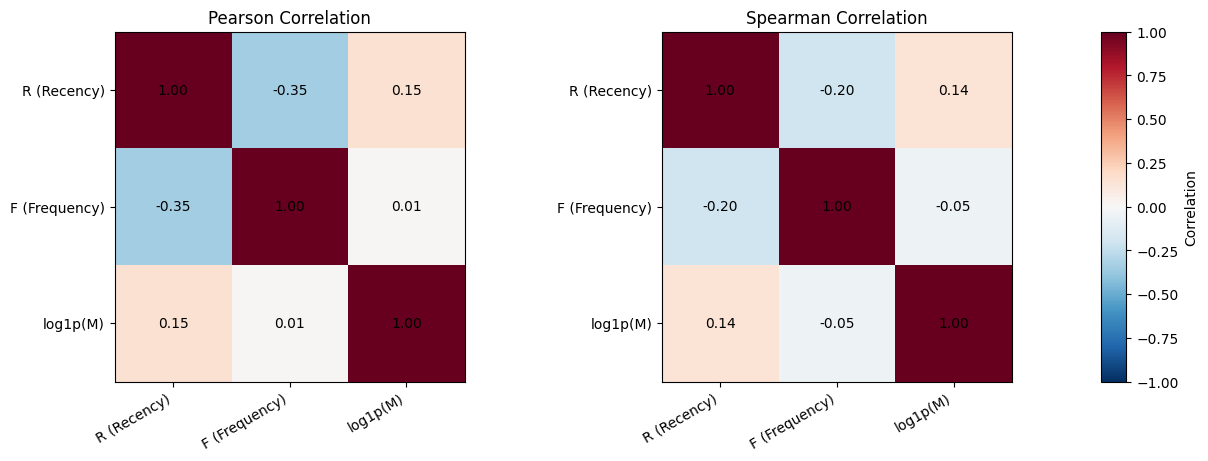

In [51]:
# Step 5: Display Pearson and Spearman correlation heatmaps horizontally

fig = plt.figure(figsize=(12, 4.5), constrained_layout=True)

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.05]
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1])
]

cax = fig.add_subplot(gs[0, 2])

correlations = [
    (pearson_corr, "Pearson Correlation"),
    (spearman_corr, "Spearman Correlation")
]

for ax, (corr, title) in zip(axes, correlations):

    im = ax.imshow(
        corr,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(3))
    ax.set_xticklabels(inputs.columns, rotation=30, ha="right")

    ax.set_yticks(range(3))
    ax.set_yticklabels(inputs.columns)

    for i in range(3):
        for j in range(3):
            ax.text(
                j, i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    ax.set_title(title)

# Shared colour bar with matching height
fig.colorbar(
    im,
    cax=cax,
    label="Correlation"
)

plt.show()


In [52]:
# Step 6: Save the results
from pathlib import Path

folder = Path("W2083147cw_data")
folder.mkdir(parents=True, exist_ok=True)

pearson_corr.to_csv(
    folder / "Pearson_Correlation.csv"
)

spearman_corr.to_csv(
    folder / "Spearman_Correlation.csv"
)

pairs_table.to_csv(
    folder / "Pairwise_Correlation_Comparison.csv",
    index=False
)

print("Correlation analysis completed and saved.")

Correlation analysis completed and saved.


### 2.5.2 Removal of Monetary

 Ward clustering on the full RFM inputs (log-transformed Monetary, standardised) is compared with Ward clustering on Recency and Frequency only (standardised). Both use the same K and the same shares.

**What is measured:**

1. ARI and a cross-tabulation between the two sets of labels.
2. Monetary profiles (median and mean, in USD billions) of the clusters from each model.
3.log1p(Monetary) by cluster: the share of Monetary variation explained by cluster membership. A drop after removal shows how much Monetary was shaping the clusters.
4. Boxplots of log1p(Monetary) by cluster for both models.

Labels, profiles, η² and ARI are saved.

In [53]:
# 2.5.2 Removal of Monetary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from IPython.display import display
from pathlib import Path

# Step 1: Use the Ward cluster count selected for Trading Activity in 2.2
K = FINAL_K["Trading activity"]

# Use the same companies as the original RFM model
shares = X_act.index

rfm_data = feat.loc[
    shares,
    ["Recency", "Frequency", "Monetary"]
].copy()

assert rfm_data.index.equals(X_act.index)
assert rfm_data.notna().all().all()

print("Companies used:", len(shares))
print("Selected cluster count:", K)

Companies used: 486
Selected cluster count: 3


In [54]:
# Step 2: Prepare and standardise Recency and Frequency

rf_data = rfm_data[["Recency", "Frequency"]]

scaler = StandardScaler()

X_rf = pd.DataFrame(
    scaler.fit_transform(rf_data),
    index=shares,
    columns=rf_data.columns
)

print("Standardised R and F features:")
display(X_rf.head())

print("Standardisation check:")
display(
    pd.DataFrame({
        "Mean": X_rf.mean(),
        "Standard_Deviation": X_rf.std(ddof=0)
    }).round(3)
)

Standardised R and F features:


,Recency,Frequency
Ticker,,
A,-0.441238,-0.744463
AAPL,-0.441238,-0.744463
ABBV,-0.441238,0.007739
ABNB,-0.441238,0.007739
ABT,-0.441238,-1.496666


Standardisation check:


,Mean,Standard_Deviation
Recency,-0.0,1.0
Frequency,-0.0,1.0


In [55]:
# Step 3: Fit the full RFM and reduced RF models

# Full RFM clustering
Z_full = linkage(
    X_act.to_numpy(),
    method="ward",
    metric="euclidean"
)

full_labels = pd.Series(
    fcluster(Z_full, t=K, criterion="maxclust"),
    index=shares,
    name="Full_RFM"
)

# Reduced R and F clustering
Z_rf = linkage(
    X_rf.to_numpy(),
    method="ward",
    metric="euclidean"
)

reduced_labels = pd.Series(
    fcluster(Z_rf, t=K, criterion="maxclust"),
    index=shares,
    name="Reduced_RF"
)

print("Actual full RFM clusters:", full_labels.nunique())
print("Actual reduced RF clusters:", reduced_labels.nunique())

Actual full RFM clusters: 3
Actual reduced RF clusters: 3


In [56]:
# Step 4: Compare the cluster memberships

ari = adjusted_rand_score(
    full_labels,
    reduced_labels
)

comparison = pd.crosstab(
    full_labels,
    reduced_labels,
    rownames=["Full RFM"],
    colnames=["R and F only"]
)

print("Cluster membership comparison:")
display(comparison)

print("Adjusted Rand Index:", round(ari, 3))

Cluster membership comparison:


R and F only,1,2,3
Full RFM,,,
1,79,0,3
2,9,59,86
3,1,66,183


Adjusted Rand Index: 0.291


In [57]:
# Step 5: Compare original Monetary values across clusters

def monetary_profile(labels):

    data = rfm_data.copy()
    data["Cluster"] = labels

    profile = data.groupby("Cluster").agg(
        Companies=("Monetary", "size"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Monetary=("Monetary", "mean")
    )

    # Convert Monetary values into USD billions
    profile["Median_Monetary"] /= 1e9
    profile["Mean_Monetary"] /= 1e9

    return profile


# Full RFM profiles
full_profile = monetary_profile(full_labels)

print("Full RFM Monetary profiles:")
display(full_profile.round(2))


# Reduced R and F profiles
reduced_profile = monetary_profile(reduced_labels)

print("Reduced R and F Monetary profiles:")
display(reduced_profile.round(2))

Full RFM Monetary profiles:


,Companies,Median_Recency,Median_Frequency,Median_Monetary,Mean_Monetary
Cluster,,,,,
1,82,54.5,2.0,17.85,47.16
2,154,11.0,3.0,39.70,80.15
3,250,11.0,3.0,11.18,11.76


Reduced R and F Monetary profiles:


,Companies,Median_Recency,Median_Frequency,Median_Monetary,Mean_Monetary
Cluster,,,,,
1,89,54.0,2.0,20.85,46.53
2,125,11.0,2.0,17.70,34.34
3,272,11.0,4.0,14.86,39.40


In [58]:
# Step 6: Calculate the variation in Monetary explained by clusters

def eta_squared(values, labels):

    data = pd.DataFrame({
        "Value": np.asarray(values, dtype=float),
        "Cluster": np.asarray(labels)
    })

    overall_mean = data["Value"].mean()

    total = (
        (data["Value"] - overall_mean) ** 2
    ).sum()

    if total == 0:
        return np.nan

    between = sum(
        len(group) * (group.mean() - overall_mean) ** 2
        for _, group in data.groupby("Cluster")["Value"]
    )

    return between / total


log_monetary = np.log1p(rfm_data["Monetary"])

eta_table = pd.DataFrame({
    "Full RFM": [
        eta_squared(log_monetary, full_labels)
    ],
    "Reduced RF": [
        eta_squared(log_monetary, reduced_labels)
    ]
}, index=["log1p(Monetary)"])

print("Monetary variation explained by cluster membership:")
display(eta_table.round(3))

Monetary variation explained by cluster membership:


,Full RFM,Reduced RF
log1p(Monetary),0.516,0.004


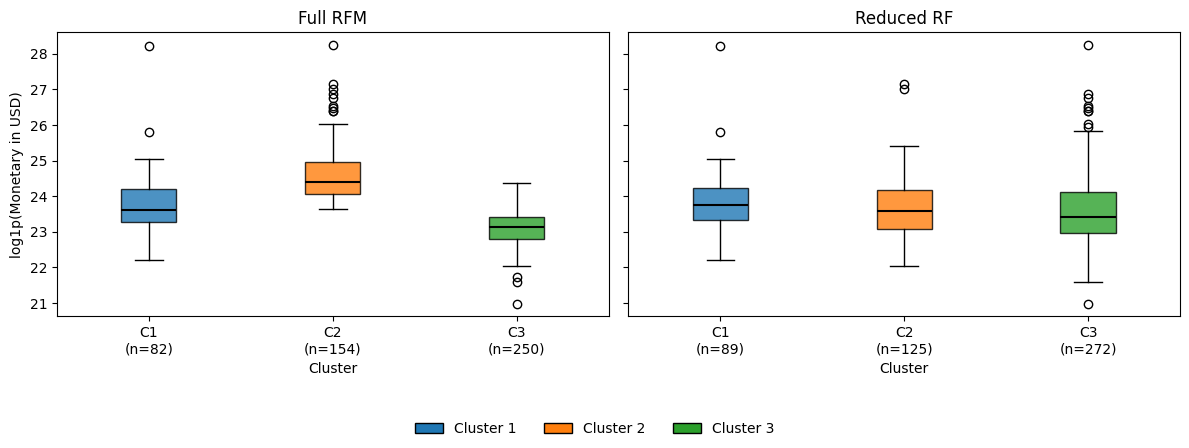

In [59]:
# Step 7: Compare Monetary distributions visually

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

# Assign consistent colours to cluster labels
cluster_ids = sorted(
    set(full_labels.unique()) | set(reduced_labels.unique())
)

palette = plt.get_cmap("tab10")

cluster_colors = {
    cluster: palette(i % 10)
    for i, cluster in enumerate(cluster_ids)
}

for ax, labels, title in [
    (axes[0], full_labels, "Full RFM"),
    (axes[1], reduced_labels, "Reduced RF")
]:

    clusters = sorted(labels.unique())

    box_data = [
        np.log1p(
            rfm_data.loc[labels == cluster, "Monetary"]
        )
        for cluster in clusters
    ]

    bp = ax.boxplot(
        box_data,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5)
    )

    # Apply different colours to each cluster
    for box, cluster in zip(bp["boxes"], clusters):
        box.set_facecolor(cluster_colors[cluster])
        box.set_edgecolor("black")
        box.set_alpha(0.8)

    ax.set_xticks(range(1, len(clusters) + 1))

    ax.set_xticklabels([
        f"C{cluster}\n(n={len(values)})"
        for cluster, values in zip(clusters, box_data)
    ])

    ax.set_title(title)
    ax.set_xlabel("Cluster")

axes[0].set_ylabel("log1p(Monetary in USD)")

# Add a common cluster colour legend
legend_handles = [
    Patch(
        facecolor=cluster_colors[c],
        edgecolor="black",
        label=f"Cluster {c}"
    )
    for c in cluster_ids
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=len(cluster_ids),
    frameon=False
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


In [60]:
# Step 8: Save all results

folder = Path("W2083147cw_data")
folder.mkdir(parents=True, exist_ok=True)

labels = pd.DataFrame({
    "Full_RFM": full_labels,
    "Reduced_RF": reduced_labels
})

labels.to_csv(
    folder / "RFM_vs_RF_Cluster_Labels.csv",
    index_label="Share"
)

full_profile.to_csv(
    folder / "Full_RFM_Monetary_Profiles.csv"
)

reduced_profile.to_csv(
    folder / "Reduced_RF_Monetary_Profiles.csv"
)

eta_table.to_csv(
    folder / "Monetary_Variation_Comparison.csv"
)

pd.DataFrame({
    "Selected_K": [K],
    "ARI": [ari],
    "Companies_Compared": [len(shares)]
}).to_csv(
    folder / "RFM_vs_RF_ARI.csv",
    index=False
)

print("Monetary removal experiment completed successfully.")

Monetary removal experiment completed successfully.


# Task 3 Business Intelligence and Critical Review

Risk clusters, shown in original units (including trading activity):


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary ($bn),Shares
Risk_Cluster,,,,,,
1,0.006,1.326,23.689,3.101,87.037,119
2,0.003,0.631,19.931,2.911,23.440,202
3,0.001,1.139,18.624,3.006,24.596,165


Activity clusters, shown in original units (including risk and return):


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary ($bn),Shares
Activity_Cluster,,,,,,
1,0.003,0.933,13.367,3.352,12.014,270
2,0.003,0.969,64.609,1.688,54.435,64
3,0.003,1.049,14.303,2.895,81.729,152


Do the two sets of groups overlap? ARI = 0.021


Activity cluster,1,2,3
Risk cluster,,,
1,49,19,51
2,117,25,60
3,104,20,41


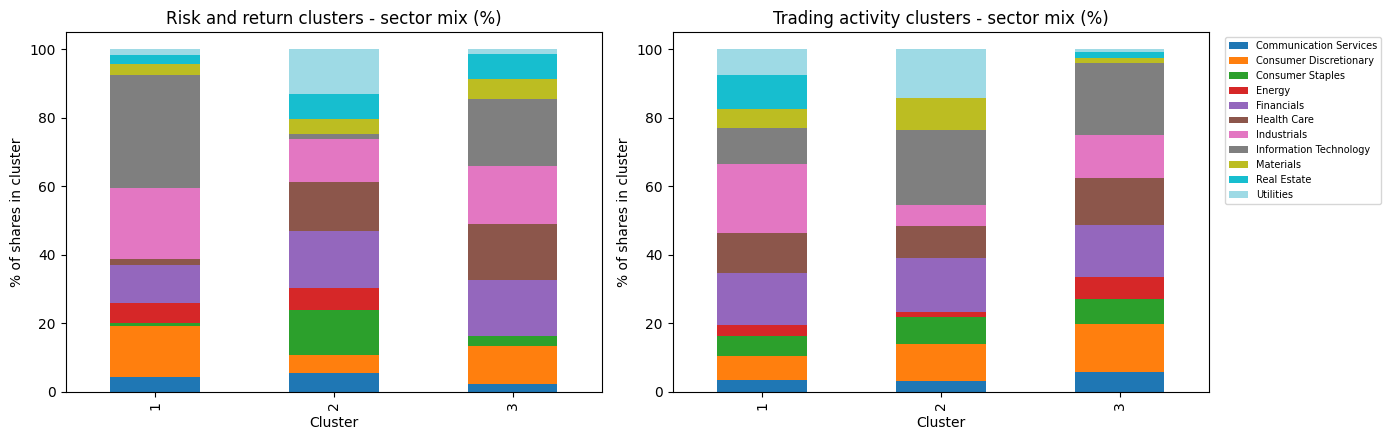

In [61]:
# 3.2.1 Risk/return clusters vs RFM clusters, with sector composition (K-means solutions)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

# Load the correct cluster assignments saved during the algorithm comparison step
saved_labels = pd.read_csv("W2083147cw_data/Algorithm_Comparison_Labels.csv", index_col="Share")

sector = sp500_df.set_index("Yahoo_Symbol")["GICS Sector"].reindex(rfm.index)
rk, ak = saved_labels["Risk_KMeans"], saved_labels["Activity_KMeans"]

both = risk_return.join(activity).assign(Risk_Cluster=rk, Activity_Cluster=ak)
both["Monetary ($bn)"] = both.pop("Monetary") / 1e9
print("Risk clusters, shown in original units (including trading activity):")
display(both.drop(columns="Activity_Cluster").groupby("Risk_Cluster").mean().round(3).join(rk.value_counts().sort_index().rename("Shares")))
print("Activity clusters, shown in original units (including risk and return):")
display(both.drop(columns="Risk_Cluster").groupby("Activity_Cluster").mean().round(3).join(ak.value_counts().sort_index().rename("Shares")))

print("Do the two sets of groups overlap? ARI =", round(adjusted_rand_score(rk, ak), 3))
display(pd.crosstab(rk, ak, rownames=["Risk cluster"], colnames=["Activity cluster"]))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (lab, title) in zip(ax, [(rk, "Risk and return clusters"), (ak, "Trading activity clusters")]):
    pd.crosstab(lab, sector, normalize="index").mul(100).plot(kind="bar", stacked=True, ax=a, colormap="tab20", legend=False)
    a.set_title(title + " - sector mix (%)")
    a.set_xlabel("Cluster")
    a.set_ylabel("% of shares in cluster")
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

In [62]:
# Compress all files into one ZIP folder
import shutil

shutil.make_archive("W2083147cw_data","zip","W2083147cw_data")

# Download the ZIP folder
from google.colab import files

files.download("W2083147cw_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>